In [1]:
# Cell 0: Patch numpy deprecated aliases (temporary, per-session)
import numpy as np
aliases = {
    'bool': bool,
    'int': int,
    'float': float,
    'object': object,
    'str': str,
    'long': int,
}
for name, val in aliases.items():
    if not hasattr(np, name):
        try:
            setattr(np, name, val)
        except Exception as e:
            print("Could not set np."+name, e)
print("Patched numpy aliases. np.bool present?:", hasattr(np, 'bool'))


Patched numpy aliases. np.bool present?: True


/tmp/ipykernel_47/2406706105.py:12: FutureWarning: In the future `np.bool` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, name):
/tmp/ipykernel_47/2406706105.py:12: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, name):
/tmp/ipykernel_47/2406706105.py:12: FutureWarning: In the future `np.str` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, name):
/tmp/ipykernel_47/2406706105.py:12: FutureWarning: In the future `np.long` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, name):


In [2]:
# Cell 1: imports, seeds, device, find DATA_ROOT automatically
import os, random, math, time
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
import timm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)

# Auto-find the inner dataset folder (the one that contains train/ or class folders)
ROOT = "/kaggle/input/fundus-image"
def find_data_root(root):
    for path, dirs, files in os.walk(root):
        if 'train' in dirs or 'valid' in dirs:
            return path
        # heuristic: if path contains >=2 subdirs that themselves contain images
        subdirs = [os.path.join(path,d) for d in dirs]
        count_with_images = 0
        for sd in subdirs[:6]:
            if os.path.isdir(sd) and any(f.lower().endswith(('jpg','png','jpeg')) for f in os.listdir(sd)[:20]):
                count_with_images += 1
        if count_with_images >= 2:
            return path
    return root

DATA_ROOT = find_data_root(ROOT)
print("Using DATA_ROOT =", DATA_ROOT)
WORK_DIR = "/kaggle/working/fundus_project"
os.makedirs(WORK_DIR, exist_ok=True)


/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

Device: cuda
Using DATA_ROOT = /kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset


In [3]:
# Cell 2: show structure and detected classes & counts
def list_top(root, depth=1):
    for p, dirs, files in os.walk(root):
        rel = os.path.relpath(p, root)
        if rel.count(os.sep) <= depth:
            print(f"{p} -> subdirs: {dirs[:10]} files: {len([f for f in files if f.lower().endswith(('jpg','png','jpeg'))])}")
list_top(DATA_ROOT, depth=1)

# Pick train root: if there is 'train' use it; else assume DATA_ROOT is the train folder with class subfolders
train_root = os.path.join(DATA_ROOT, 'train') if os.path.isdir(os.path.join(DATA_ROOT,'train')) else DATA_ROOT
print("train_root =", train_root)

classes = sorted([d for d in os.listdir(train_root) if os.path.isdir(os.path.join(train_root, d))])
print("Detected classes:", classes)
for c in classes:
    p = os.path.join(train_root, c)
    imgs = [f for f in os.listdir(p) if f.lower().endswith(('jpg','png','jpeg'))]
    print(f"  {c}: {len(imgs)} images")


/kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset -> subdirs: ['valid', 'train'] files: 0
/kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/valid -> subdirs: ['amd', 'diabetes', 'normal', 'cataract'] files: 0
/kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/valid/amd -> subdirs: [] files: 100
/kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/valid/diabetes -> subdirs: [] files: 100
/kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/valid/normal -> subdirs: [] files: 100
/kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dat

Sample image: /kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/train/amd/1269.jpg


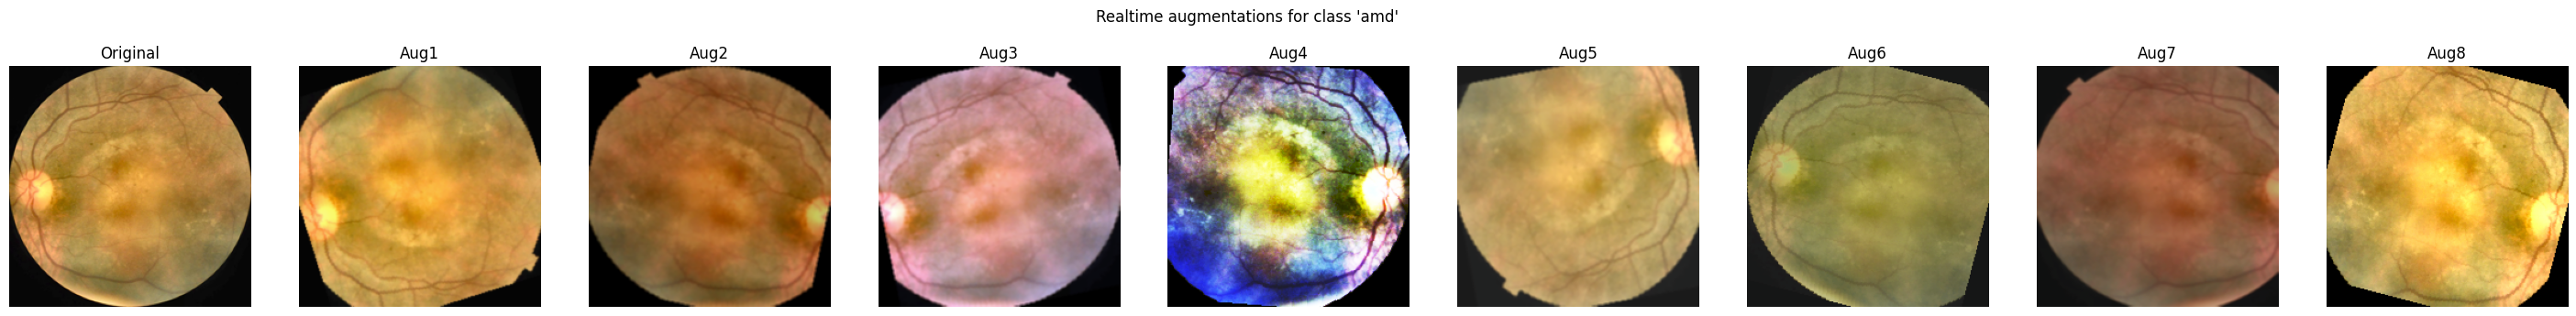

In [4]:
# Cell 3: Transform definitions (runtime augmentation) and show samples
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.2),
    T.RandomRotation(20),
    T.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15, hue=0.05),
    T.RandomAutocontrast(p=0.2),
    T.RandomEqualize(p=0.1),
    # If GaussianBlur caused earlier problems for you, comment the next line out
    T.GaussianBlur(kernel_size=(3,3), sigma=(0.1,2.0)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

val_transform = T.Compose([
    T.Resize(int(IMG_SIZE*1.05)),
    T.CenterCrop(IMG_SIZE),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# helper to display tensor
def tensor_to_img(tensor):
    arr = tensor.cpu().numpy().transpose(1,2,0)
    arr = arr * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    arr = np.clip(arr, 0, 1)
    return arr

# Display real-time augmentations for one sample image
sample_class = classes[0]
sample_dir = os.path.join(train_root, sample_class)
sample_files = [f for f in os.listdir(sample_dir) if f.lower().endswith(('jpg','png','jpeg'))]
assert len(sample_files)>0, "No images found in class folder."
sample_path = os.path.join(sample_dir, sample_files[0])
print("Sample image:", sample_path)

orig = Image.open(sample_path).convert('RGB')
n = 8
fig, axs = plt.subplots(1, n+1, figsize=(4*(n+1), 4))
axs[0].imshow(orig.resize((IMG_SIZE, IMG_SIZE))); axs[0].set_title("Original"); axs[0].axis('off')
for i in range(n):
    aug_t = train_transform(orig)
    axs[i+1].imshow(tensor_to_img(aug_t)); axs[i+1].set_title(f"Aug{i+1}"); axs[i+1].axis('off')
plt.suptitle(f"Realtime augmentations for class '{sample_class}'")
plt.show()


In [5]:
# Cell 4: build lists of file paths and labels (for K-fold)
# We will use these arrays for stratified splitting
paths = []
labels = []
class_to_idx = {c:i for i,c in enumerate(classes)}
for c in classes:
    p = os.path.join(train_root, c)
    files = [f for f in os.listdir(p) if f.lower().endswith(('jpg','png','jpeg'))]
    for f in files:
        paths.append(os.path.join(p,f))
        labels.append(class_to_idx[c])
paths = np.array(paths)
labels = np.array(labels, dtype=np.int32)
print("Total images:", len(paths))
for i,c in enumerate(classes):
    print(i, c, np.sum(labels==i))


Total images: 1594
0 amd 394
1 cataract 400
2 diabetes 400
3 normal 400


In [6]:
# Cell 5: MixUp and CutMix utilities
import numpy as np, torch

def mixup_data(x, y, alpha=1.0):
    if alpha <= 0:
        return x, y, None, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def cutmix_data(x, y, alpha=1.0):
    if alpha <= 0:
        return x, y, None, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size, c, h, w = x.size()
    index = torch.randperm(batch_size).to(x.device)
    cut_rat = np.sqrt(1. - lam)
    cut_w = int(w * cut_rat); cut_h = int(h * cut_rat)
    cx = np.random.randint(w); cy = np.random.randint(h)
    x1 = np.clip(cx - cut_w // 2, 0, w); x2 = np.clip(cx + cut_w // 2, 0, w)
    y1 = np.clip(cy - cut_h // 2, 0, h); y2 = np.clip(cy + cut_h // 2, 0, h)
    x[:, :, y1:y2, x1:x2] = x[index, :, y1:y2, x1:x2]
    lam_adj = 1.0 - ((x2-x1)*(y2-y1) / (w*h))
    y_a, y_b = y, y[index]
    return x, y_a, y_b, lam_adj


In [7]:
# Cell 6: model factories
NUM_CLASSES = len(classes)

def make_efficientnet_b4(num_classes=NUM_CLASSES):
    return timm.create_model('efficientnet_b4', pretrained=True, num_classes=num_classes)

def make_swin_tiny(num_classes=NUM_CLASSES):
    return timm.create_model('swin_tiny_patch4_window7_224', pretrained=True, num_classes=num_classes)

def make_convnext_base(num_classes=NUM_CLASSES):
    return timm.create_model('convnext_base', pretrained=True, num_classes=num_classes)

# example: dual stream fusion (optional, not used by default)
class DualFusion(nn.Module):
    def __init__(self, cnn_name='efficientnet_b4', vit_name='swin_tiny', num_classes=NUM_CLASSES):
        super().__init__()
        self.cnn = timm.create_model(cnn_name, pretrained=True, num_classes=0, global_pool='avg')
        self.vit = timm.create_model(vit_name, pretrained=True, num_classes=0, global_pool='avg')
        dim = self.cnn.num_features + self.vit.num_features
        self.fc = nn.Sequential(nn.Linear(dim, 512), nn.ReLU(), nn.Dropout(0.3), nn.Linear(512, num_classes))
    def forward(self, x):
        f1 = self.cnn(x); f2 = self.vit(x)
        return self.fc(torch.cat([f1,f2], dim=1))


In [8]:
# Cell 7: training & validation utilities
from torch.cuda.amp import autocast, GradScaler
scaler = GradScaler()

def get_class_weights(labels, num_classes=NUM_CLASSES):
    unique, counts = np.unique(labels, return_counts=True)
    counts_full = np.zeros(num_classes, dtype=float); counts_full[unique] = counts
    w = 1.0 / (counts_full + 1e-9)
    w = w / w.sum() * num_classes
    return torch.tensor(w, dtype=torch.float32).to(DEVICE)

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None):
        super().__init__(); self.gamma = gamma; self.weight = weight
    def forward(self, logits, targets):
        ce = nn.functional.cross_entropy(logits, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce)
        loss = ((1-pt)**self.gamma * ce).mean()
        return loss

def train_epoch(model, loader, optimizer, loss_fn, mixup_alpha=0.0, cutmix_alpha=0.0):
    model.train()
    running = 0.0
    for imgs, labels in loader:
        imgs = imgs.to(DEVICE); labels = labels.to(DEVICE)
        optimizer.zero_grad()
        with autocast():
            if mixup_alpha > 0:
                imgs_m, ya, yb, lam = mixup_data(imgs, labels, alpha=mixup_alpha)
                outputs = model(imgs_m)
                loss = lam * loss_fn(outputs, ya) + (1-lam) * loss_fn(outputs, yb)
            elif cutmix_alpha > 0:
                imgs_m, ya, yb, lam = cutmix_data(imgs, labels, alpha=cutmix_alpha)
                outputs = model(imgs_m)
                loss = lam * loss_fn(outputs, ya) + (1-lam) * loss_fn(outputs, yb)
            else:
                outputs = model(imgs)
                loss = loss_fn(outputs, labels)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        running += loss.item() * imgs.size(0)
    return running / len(loader.dataset)

def validate_epoch(model, loader, loss_fn):
    model.eval()
    all_probs=[]; all_preds=[]; all_labels=[]
    val_loss = 0.0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(DEVICE); labels = labels.to(DEVICE)
            outputs = model(imgs)
            loss = loss_fn(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            probs = nn.functional.softmax(outputs, dim=1).cpu().numpy()
            preds = probs.argmax(axis=1)
            all_probs.append(probs); all_preds.append(preds); all_labels.append(labels.cpu().numpy())
    return val_loss/len(loader.dataset), np.vstack(all_probs), np.concatenate(all_preds), np.concatenate(all_labels)

# Simple NumPy metrics
def confusion_matrix_np(y_true, y_pred, num_classes=NUM_CLASSES):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t,p in zip(y_true, y_pred): cm[int(t), int(p)] += 1
    return cm
def precision_recall_f1(y_true, y_pred, num_classes=NUM_CLASSES):
    cm = confusion_matrix_np(y_true,y_pred,num_classes)
    precision = np.zeros(num_classes); recall=np.zeros(num_classes); f1=np.zeros(num_classes)
    for k in range(num_classes):
        tp=cm[k,k]; fp=cm[:,k].sum()-tp; fn=cm[k,:].sum()-tp
        precision[k]=tp/(tp+fp) if (tp+fp)>0 else 0.0
        recall[k]=tp/(tp+fn) if (tp+fn)>0 else 0.0
        f1[k]=2*precision[k]*recall[k]/(precision[k]+recall[k]) if (precision[k]+recall[k])>0 else 0.0
    acc = (y_true==y_pred).mean()
    return {'accuracy':acc, 'precision_per_class':precision, 'recall_per_class':recall, 'f1_per_class':f1, 'confusion_matrix':cm}


/tmp/ipykernel_47/1204490776.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


In [9]:
# Cell 8: Smoke test training (1 epoch on tiny subset)
N_SMOKE = 64
indices = np.arange(len(paths)); np.random.RandomState(SEED).shuffle(indices)
smoke_idx = indices[:N_SMOKE]
from torch.utils.data import Dataset
class TempDS(Dataset):
    def __init__(self, paths_arr, labels_arr, transform):
        self.paths = paths_arr; self.labels = labels_arr; self.transform = transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        img = self.transform(img)
        return img, int(self.labels[i])

tr_paths = paths[smoke_idx[:48]]; tr_labels = labels[smoke_idx[:48]]
va_paths = paths[smoke_idx[48:]]; va_labels = labels[smoke_idx[48:]]

tr_ds = TempDS(tr_paths, tr_labels, train_transform)
va_ds = TempDS(va_paths, va_labels, val_transform)
tr_loader = DataLoader(tr_ds, batch_size=8, shuffle=True, num_workers=2, pin_memory=True)
va_loader = DataLoader(va_ds, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

model = make_efficientnet_b4().to(DEVICE)
class_weights = get_class_weights(labels)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)
opt = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)

print("Running smoke training (1 epoch)...")
tr_loss = train_epoch(model, tr_loader, opt, loss_fn, mixup_alpha=0.0)
val_loss, val_probs, val_preds, val_labels = validate_epoch(model, va_loader, loss_fn)
print("Smoke val loss:", val_loss)
print("Smoke metrics:", precision_recall_f1(val_labels, val_preds))


model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

Running smoke training (1 epoch)...


/tmp/ipykernel_47/1204490776.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Smoke val loss: 1.7795482873916626
Smoke metrics: {'accuracy': 0.4375, 'precision_per_class': array([1.  , 0.8 , 0.  , 0.25]), 'recall_per_class': array([0.16666667, 1.        , 0.        , 1.        ]), 'f1_per_class': array([0.28571429, 0.88888889, 0.        , 0.4       ]), 'confusion_matrix': array([[1, 0, 2, 3],
       [0, 4, 0, 0],
       [0, 1, 0, 3],
       [0, 0, 0, 2]])}


In [10]:
# =========================================================
# Cell 9: Full 5-fold training (EfficientNet-B4) WITH LOGGING
# =========================================================

K = 5
EPOCHS = 18
BATCH = 16
PATIENCE = 3

# ---------- Stratified K-Fold (no sklearn) ----------
def stratified_kfold_indices(labels, n_splits=5, seed=SEED):
    labels = np.array(labels)
    idxs = np.arange(len(labels))
    folds = [[] for _ in range(n_splits)]
    rng = np.random.RandomState(seed)
    for cls in np.unique(labels):
        cls_idx = idxs[labels == cls]
        rng.shuffle(cls_idx)
        for i, ix in enumerate(cls_idx):
            folds[i % n_splits].append(ix)
    splits = []
    for k in range(n_splits):
        val = np.array(folds[k])
        train = np.setdiff1d(idxs, val)
        splits.append((train, val))
    return splits

splits = stratified_kfold_indices(labels, n_splits=K)

# ---------- OOF storage ----------
oof_probs = np.zeros((len(paths), NUM_CLASSES), dtype=np.float32)
oof_targets = np.zeros(len(paths), dtype=np.int32)

# ---------- Fold history storage ----------
all_fold_histories = []

# =========================================================
# K-FOLD LOOP
# =========================================================
for fold, (train_idx, val_idx) in enumerate(splits):

    print(f"\n=== Fold {fold+1}/{K} ===")

    tr_paths = paths[train_idx]
    tr_labels = labels[train_idx]
    va_paths = paths[val_idx]
    va_labels = labels[val_idx]

    tr_ds = TempDS(tr_paths, tr_labels, train_transform)
    va_ds = TempDS(va_paths, va_labels, val_transform)

    tr_loader = DataLoader(
        tr_ds, batch_size=BATCH, shuffle=True,
        num_workers=4, pin_memory=True
    )
    va_loader = DataLoader(
        va_ds, batch_size=BATCH, shuffle=False,
        num_workers=2, pin_memory=True
    )

    model = make_efficientnet_b4().to(DEVICE)

    weights_fold = get_class_weights(tr_labels)
    loss_fn = nn.CrossEntropyLoss(weight=weights_fold)

    opt = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

    best_val = 1e9
    no_imp = 0
    ckpt = os.path.join(WORK_DIR, f"effib4_fold{fold}.pth")

    # ---------- INIT LOGGING LISTS ----------
    train_loss_list = []
    val_loss_list   = []
    val_acc_list    = []

    # =====================================================
    # EPOCH LOOP
    # =====================================================
    for ep in range(1, EPOCHS + 1):

        # ---- TRAIN ----
        tr_loss = train_epoch(
            model, tr_loader, opt, loss_fn, mixup_alpha=0.2
        )

        # ---- VALIDATE ----
        val_loss, val_probs, val_preds, val_labels = validate_epoch(
            model, va_loader, loss_fn
        )

        val_acc = (val_preds == val_labels).mean()

        # ---- SAVE HISTORY ----
        train_loss_list.append(tr_loss)
        val_loss_list.append(val_loss)
        val_acc_list.append(val_acc)

        print(
            f"Fold {fold+1} | Epoch {ep:02d} | "
            f"Train Loss: {tr_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        # ---- SCHEDULER ----
        sched.step()

        # ---- EARLY STOPPING ----
        if val_loss < best_val - 1e-4:
            best_val = val_loss
            torch.save(model.state_dict(), ckpt)
            no_imp = 0
        else:
            no_imp += 1

        if no_imp >= PATIENCE:
            print("Early stopping")
            break

    # ---------- SAVE FOLD HISTORY ----------
    fold_history = {
        "train_loss": train_loss_list,
        "val_loss": val_loss_list,
        "val_acc": val_acc_list
    }
    all_fold_histories.append(fold_history)

    # ---------- LOAD BEST MODEL & STORE OOF ----------
    model.load_state_dict(torch.load(ckpt))
    model.eval()

    all_probs = []
    with torch.no_grad():
        for imgs, labs in va_loader:
            imgs = imgs.to(DEVICE)
            logits = model(imgs)
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            all_probs.append(probs)

    all_probs = np.vstack(all_probs)
    oof_probs[val_idx] = all_probs
    oof_targets[val_idx] = va_labels

    print(f"Stored OOF for fold {fold}, {len(val_idx)} samples.")

print("K-fold training done. OOF shape:", oof_probs.shape)

# ---------- SAVE OOF ----------
np.save(os.path.join(WORK_DIR, "oof_probs.npy"), oof_probs)
np.save(os.path.join(WORK_DIR, "oof_targets.npy"), oof_targets)



=== Fold 1/5 ===


/tmp/ipykernel_47/1204490776.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Fold 1 | Epoch 01 | Train Loss: 1.4046 | Val Loss: 0.8222 | Val Acc: 0.6897
Fold 1 | Epoch 02 | Train Loss: 0.9816 | Val Loss: 0.7190 | Val Acc: 0.7273
Fold 1 | Epoch 03 | Train Loss: 0.8571 | Val Loss: 0.5922 | Val Acc: 0.7774
Fold 1 | Epoch 04 | Train Loss: 0.7747 | Val Loss: 0.5006 | Val Acc: 0.7994
Fold 1 | Epoch 05 | Train Loss: 0.7744 | Val Loss: 0.5251 | Val Acc: 0.8056
Fold 1 | Epoch 06 | Train Loss: 0.7234 | Val Loss: 0.5005 | Val Acc: 0.7994
Fold 1 | Epoch 07 | Train Loss: 0.7104 | Val Loss: 0.4476 | Val Acc: 0.8401
Fold 1 | Epoch 08 | Train Loss: 0.6502 | Val Loss: 0.4270 | Val Acc: 0.8558
Fold 1 | Epoch 09 | Train Loss: 0.7043 | Val Loss: 0.4512 | Val Acc: 0.8464
Fold 1 | Epoch 10 | Train Loss: 0.6541 | Val Loss: 0.3719 | Val Acc: 0.8683
Fold 1 | Epoch 11 | Train Loss: 0.6356 | Val Loss: 0.3821 | Val Acc: 0.8558
Fold 1 | Epoch 12 | Train Loss: 0.6477 | Val Loss: 0.3645 | Val Acc: 0.8840
Fold 1 | Epoch 13 | Train Loss: 0.6151 | Val Loss: 0.3865 | Val Acc: 0.8558
Fold 1 | Epo

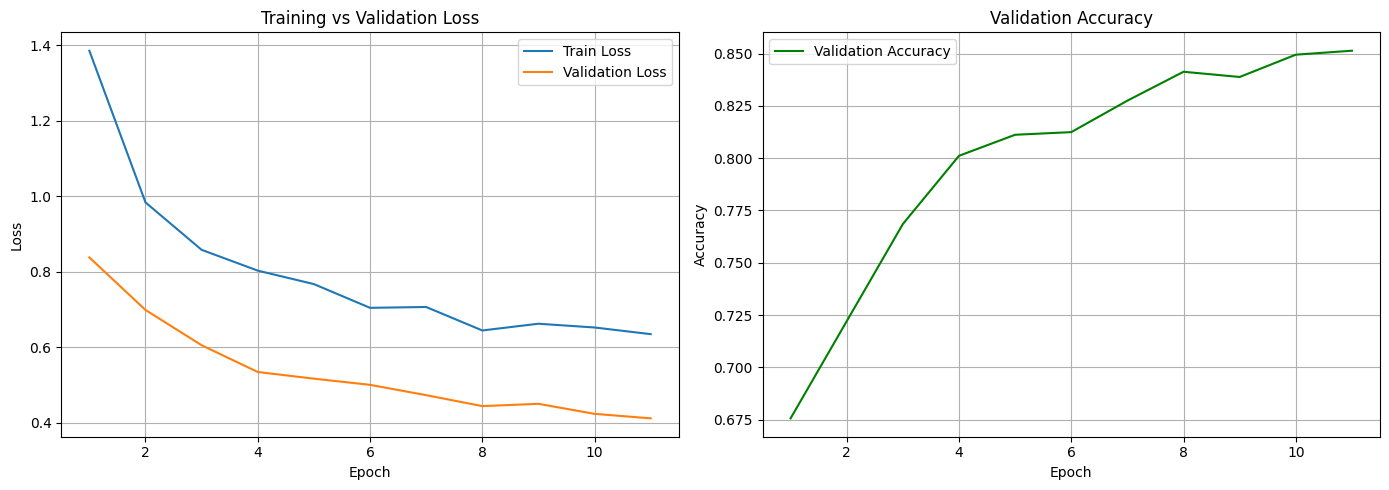

In [11]:
# =========================================================
# Plot averaged Training / Validation curves
# =========================================================
import matplotlib.pyplot as plt
import numpy as np

min_epochs = min(len(f["train_loss"]) for f in all_fold_histories)

avg_train_loss = np.mean(
    [f["train_loss"][:min_epochs] for f in all_fold_histories], axis=0
)
avg_val_loss = np.mean(
    [f["val_loss"][:min_epochs] for f in all_fold_histories], axis=0
)
avg_val_acc = np.mean(
    [f["val_acc"][:min_epochs] for f in all_fold_histories], axis=0
)

epochs = range(1, min_epochs + 1)

plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.plot(epochs, avg_train_loss, label="Train Loss")
plt.plot(epochs, avg_val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(epochs, avg_val_acc, label="Validation Accuracy", color="green")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("training_validation_curves.png", dpi=300)
plt.show()


In [18]:
# Cell 10: OOF evaluation
y_true = oof_targets
y_pred = oof_probs.argmax(axis=1)
print("Overall accuracy:", (y_true==y_pred).mean())
print("Per-class counts:", {classes[i]: int((y_true==i).sum()) for i in range(NUM_CLASSES)})
print("Confusion matrix:\n", confusion_matrix_np(y_true, y_pred, NUM_CLASSES))
print("Precision/Recall/F1:", precision_recall_f1(y_true, y_pred, NUM_CLASSES))
# simple per-class AUC OVR (trapezoid)
def roc_auc_ovr(y_true, y_prob):
    aucs=[] 
    for k in range(NUM_CLASSES):
        bin_true = (y_true==k).astype(int); scores=y_prob[:,k]
        order=np.argsort(-scores); t=bin_true[order]; tp=np.cumsum(t); fp=np.cumsum(1-t)
        P=tp[-1]; N=fp[-1]
        if P==0 or N==0: aucs.append(np.nan); continue
        tpr=tp/P; fpr=fp/N
        fpr_full=np.concatenate(([0.], fpr, [1.])); tpr_full=np.concatenate(([0.], tpr, [1.]))
        auc=np.trapz(tpr_full, fpr_full); aucs.append(auc)
    return np.array(aucs), np.nanmean(aucs)
aucs, mac = roc_auc_ovr(y_true, oof_probs)
print("Per-class AUC:", aucs, "Macro AUC:", mac)


Overall accuracy: 0.8613550815558344
Per-class counts: {'amd': 394, 'cataract': 400, 'diabetes': 400, 'normal': 400}
Confusion matrix:
 [[297  17  53  27]
 [ 14 377   1   8]
 [ 25   2 319  54]
 [  5   1  14 380]]
Precision/Recall/F1: {'accuracy': 0.8613550815558344, 'precision_per_class': array([0.87096774, 0.94962217, 0.82428941, 0.81023454]), 'recall_per_class': array([0.75380711, 0.9425    , 0.7975    , 0.95      ]), 'f1_per_class': array([0.80816327, 0.94604768, 0.81067344, 0.87456847]), 'confusion_matrix': array([[297,  17,  53,  27],
       [ 14, 377,   1,   8],
       [ 25,   2, 319,  54],
       [  5,   1,  14, 380]])}
Per-class AUC: [0.95771785 0.99411223 0.94972571 0.9757768 ] Macro AUC: 0.9693331478670849


In [19]:
# Cell A: Save OOF and basic artifacts
import json, os, numpy as np

# Ensure WORK_DIR exists
os.makedirs(WORK_DIR, exist_ok=True)

# OOF arrays already present: oof_probs, oof_targets
np.save(os.path.join(WORK_DIR, "oof_probs.npy"), oof_probs)
np.save(os.path.join(WORK_DIR, "oof_targets.npy"), oof_targets)

# Simple summary
summary = {
    "num_images": int(len(paths)),
    "classes": classes,
    "oof_shape": list(oof_probs.shape),
    "accuracy_oof": float((oof_targets == oof_probs.argmax(axis=1)).mean())
}
with open(os.path.join(WORK_DIR, "summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

print("Saved OOF, summary to", WORK_DIR)
print("Accuracy OOF:", summary["accuracy_oof"])


Saved OOF, summary to /kaggle/working/fundus_project
Accuracy OOF: 0.8613550815558344


In [20]:
# Cell B: TTA inference helper (returns averaged probs)
import torch
from torchvision import transforms

# create several deterministic augmentations for TTA (no randomness except flips/rot)
tta_transforms = [
    T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.RandomHorizontalFlip(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.RandomVerticalFlip(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.RandomResizedCrop(IMG_SIZE, scale=(0.9,1.0)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
]

def tta_predict(model, pil_img, device=DEVICE, tta_list=tta_transforms):
    model.eval()
    probs = []
    with torch.no_grad():
        for tfm in tta_list:
            x = tfm(pil_img).unsqueeze(0).to(device)
            logits = model(x)
            p = nn.functional.softmax(logits, dim=1).cpu().numpy()
            probs.append(p)
    avg = np.mean(np.vstack(probs), axis=0)
    return avg  # shape (1, num_classes)

# quick example using fold0 checkpoint
ckpt0 = os.path.join(WORK_DIR, "effib4_fold0.pth")
if os.path.exists(ckpt0):
    model0 = make_efficientnet_b4().to(DEVICE)
    model0.load_state_dict(torch.load(ckpt0))
    print("Loaded model for TTA:", ckpt0)


Loaded model for TTA: /kaggle/working/fundus_project/effib4_fold0.pth


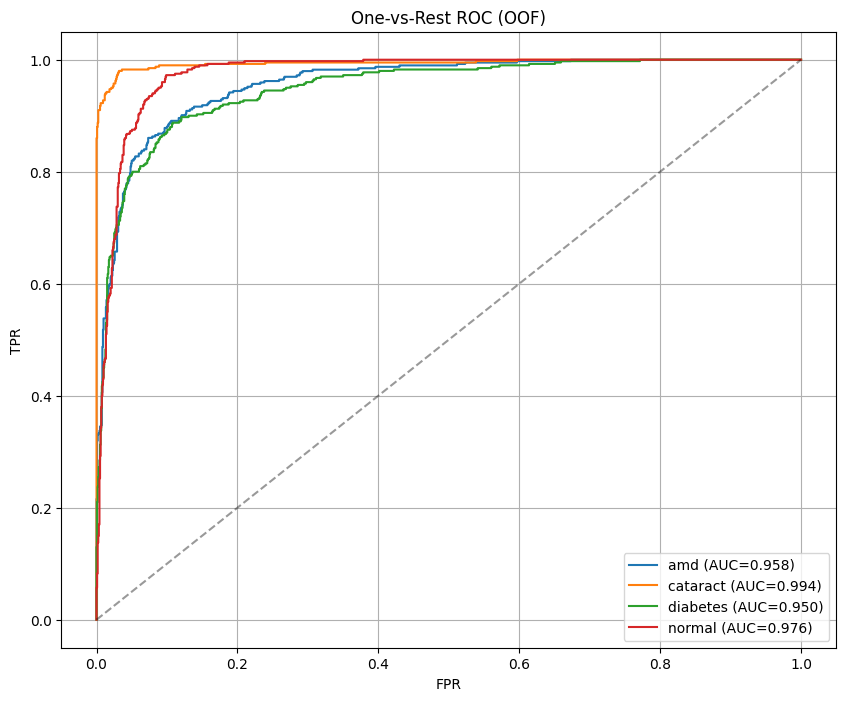

Per-class AUCs: {'amd': 0.9577178510998307, 'cataract': 0.9941122278056952, 'diabetes': 0.9497257118927973, 'normal': 0.9757768006700167}


In [21]:
# Cell C: Plot ROC curves (OVR) and compute AUC per class (uses trapezoid)
import matplotlib.pyplot as plt, numpy as np

def roc_points(y_true_bin, scores):
    # compute FPR, TPR arrays for binary
    order = np.argsort(-scores)
    t = y_true_bin[order]
    tp = np.cumsum(t)
    fp = np.cumsum(1 - t)
    P = tp[-1] if len(tp)>0 else 0
    N = fp[-1] if len(fp)>0 else 0
    if P==0:
        return np.array([0,1]), np.array([0,1]), np.nan
    tpr = tp / P
    fpr = fp / (N if N>0 else 1)
    fpr_full = np.concatenate(([0.], fpr, [1.]))
    tpr_full = np.concatenate(([0.], tpr, [1.]))
    auc = np.trapz(tpr_full, fpr_full)
    return fpr_full, tpr_full, auc

plt.figure(figsize=(10,8))
aucs = []
for k, cname in enumerate(classes):
    ybin = (oof_targets == k).astype(int)
    scores = oof_probs[:, k]
    fpr, tpr, auc = roc_points(ybin, scores)
    aucs.append(auc)
    plt.plot(fpr, tpr, label=f"{cname} (AUC={auc:.3f})")
plt.plot([0,1],[0,1],"k--", alpha=0.4)
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("One-vs-Rest ROC (OOF)"); plt.legend(); plt.grid(True)
plt.show()

print("Per-class AUCs:", {classes[i]: float(aucs[i]) for i in range(len(classes))})


In [22]:
# Cell D: Bootstrap CI for accuracy & macro AUC (1000 resamples; reduce to 500 if slow)
import numpy as np
def bootstrap_ci(y_true, y_pred, y_prob=None, metric='accuracy', n_boot=1000, seed=SEED):
    rng = np.random.RandomState(seed)
    vals = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        yt = y_true[idx]; yp = y_pred[idx]
        if metric=='accuracy':
            vals.append((yt==yp).mean())
        elif metric=='auc':
            # macro OVR auc
            aucs = []
            for k in range(len(classes)):
                yb = (yt==k).astype(int)
                sc = y_prob[idx, k]
                # quick trapezoid
                order = np.argsort(-sc); t = yb[order]; tp=np.cumsum(t); fp=np.cumsum(1-t)
                P=tp[-1] if len(tp)>0 else 0; N=fp[-1] if len(fp)>0 else 0
                if P==0 or N==0:
                    aucs.append(np.nan); continue
                tpr = tp/P; fpr = fp/N
                fpr_full=np.concatenate(([0.], fpr, [1.])); tpr_full=np.concatenate(([0.], tpr, [1.]))
                aucs.append(np.trapz(tpr_full, fpr_full))
            vals.append(np.nanmean(aucs))
    vals = np.array(vals)
    return np.percentile(vals, 2.5), np.percentile(vals, 97.5)

y_pred = oof_probs.argmax(axis=1)
acc_ci = bootstrap_ci(oof_targets, y_pred, y_prob=oof_probs, metric='accuracy', n_boot=500)
auc_ci = bootstrap_ci(oof_targets, y_pred, y_prob=oof_probs, metric='auc', n_boot=500)
print("Accuracy 95% CI:", acc_ci)
print("Macro AUC 95% CI:", auc_ci)


Accuracy 95% CI: (0.842534504391468, 0.8773682559598495)
Macro AUC 95% CI: (0.9633796354256415, 0.9748236818734757)


Best temperature (grid search): 0.9 NLL: 0.38948026


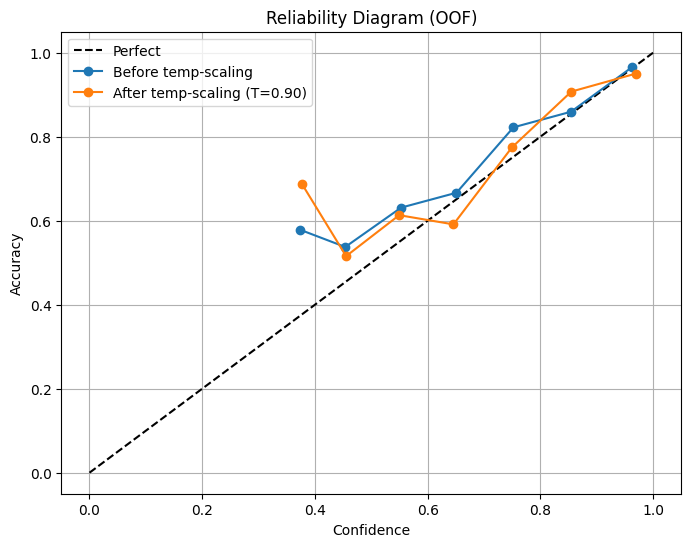

In [23]:
# Cell E: Temperature scaling (simple) + reliability diagram
import torch.nn.functional as F
import numpy as np
from sklearn.isotonic import IsotonicRegression  # if sklearn present; else skip

# Temperature scaling: train temperature on a validation set (use OOF as 'val' here)
# We'll fit temperature by minimizing NLL on OOF (simple grid search)
logits = np.log(np.clip(oof_probs, 1e-12, 1.0))  # approximate logits via log-probs (only for temp scaling demo)
# grid search temperatures
temps = np.concatenate((np.linspace(0.5,1.5,21), np.linspace(1.6,3.0,15)))
best_t = 1.0; best_nll = 1e9
y = oof_targets
for t in temps:
    p = np.exp(logits / t)
    p = p / p.sum(axis=1, keepdims=True)
    # NLL
    nll = -np.mean(np.log(p[np.arange(len(y)), y] + 1e-12))
    if nll < best_nll:
        best_nll = nll; best_t = t
print("Best temperature (grid search):", best_t, "NLL:", best_nll)

# Apply temp scaling
p_temp = np.exp(logits / best_t)
p_temp = p_temp / p_temp.sum(axis=1, keepdims=True)

# Reliability diagram (expected calibration)
def reliability_diagram(y_true, probs, n_bins=10):
    confidences = np.max(probs, axis=1)
    preds = np.argmax(probs, axis=1)
    bins = np.linspace(0,1,n_bins+1)
    bin_centers=[]; accs=[]; confs=[]
    for i in range(n_bins):
        mask = (confidences >= bins[i]) & (confidences < bins[i+1])
        if mask.sum()==0:
            bin_centers.append((bins[i]+bins[i+1])/2)
            accs.append(np.nan); confs.append(np.nan)
            continue
        bin_centers.append((bins[i]+bins[i+1])/2)
        accs.append((y_true[mask]==preds[mask]).mean())
        confs.append(confidences[mask].mean())
    return np.array(bin_centers), np.array(accs), np.array(confs)

bc, accs, confs = reliability_diagram(oof_targets, oof_probs, n_bins=10)
bc_t, accs_t, confs_t = reliability_diagram(oof_targets, p_temp, n_bins=10)

plt.figure(figsize=(8,6))
plt.plot([0,1],[0,1],"k--", label="Perfect")
plt.plot(confs, accs, marker='o', label='Before temp-scaling')
plt.plot(confs_t, accs_t, marker='o', label=f'After temp-scaling (T={best_t:.2f})')
plt.xlabel("Confidence"); plt.ylabel("Accuracy"); plt.title("Reliability Diagram (OOF)")
plt.legend(); plt.grid(True)
plt.show()


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1830: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


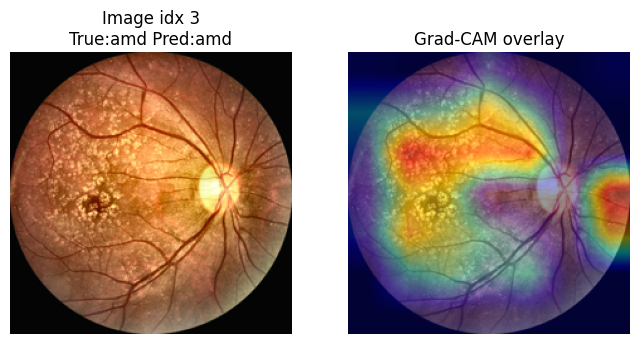

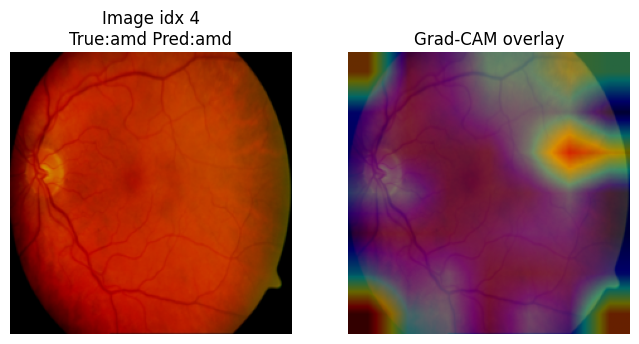

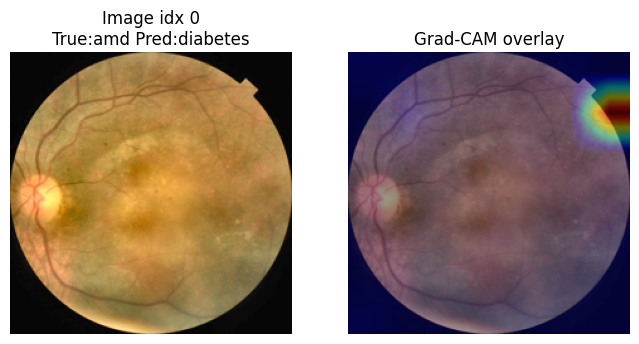

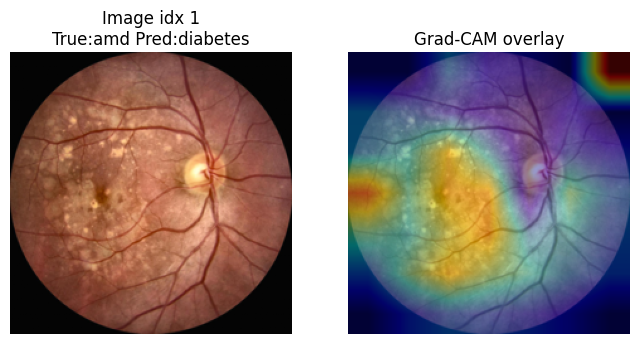

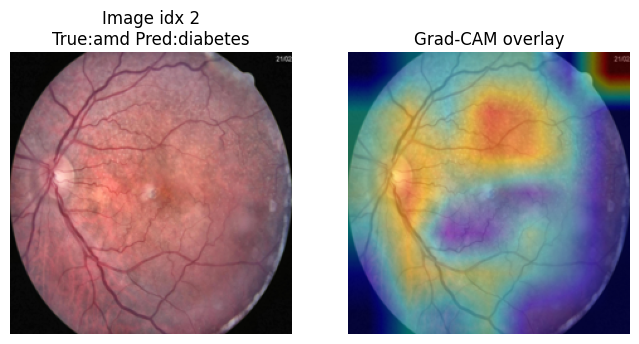

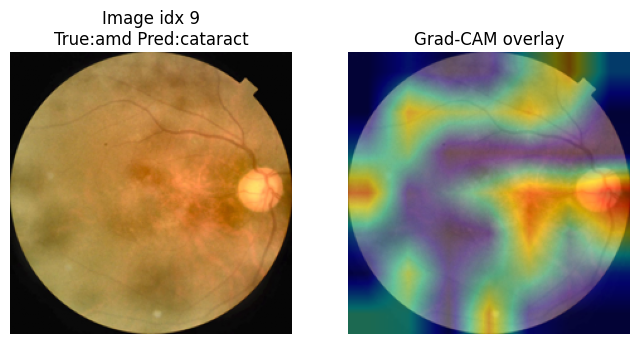

In [24]:
# Cell F: Grad-CAM (pure PyTorch) and visualization
import torch
import cv2
from PIL import Image
import matplotlib.pyplot as plt

def grad_cam(model, input_tensor, target_class=None, target_layer_name=None):
    model.zero_grad()
    activations={}; gradients={}
    # find last conv if not provided
    if target_layer_name is None:
        last_conv = None
        for n,m in model.named_modules():
            if isinstance(m, torch.nn.Conv2d):
                last_conv = n
        target_layer_name = last_conv
    # register hooks
    module = dict(model.named_modules())[target_layer_name]
    def fwd(m, inp, out): activations['val'] = out.detach()
    def bwd(m, gin, gout): gradients['val'] = gout[0].detach()
    fh = module.register_forward_hook(fwd); bh = module.register_backward_hook(bwd)
    outputs = model(input_tensor)
    if target_class is None:
        target_class = int(outputs.argmax(dim=1).item())
    loss = outputs[0, target_class]
    loss.backward(retain_graph=True)
    act = activations['val'][0]   # [C,h,w]
    grad = gradients['val'][0]    # [C,h,w]
    weights = grad.view(grad.shape[0], -1).mean(dim=1)
    cam = torch.zeros(act.shape[1:], device=act.device)
    for i,w in enumerate(weights): cam += w * act[i]
    cam = torch.relu(cam).cpu().numpy()
    cam = cam - cam.min()
    if cam.max() != 0: cam = cam / cam.max()
    cam = cv2.resize(cam, (input_tensor.shape[3], input_tensor.shape[2]))
    fh.remove(); bh.remove()
    return cam

# pick 6 examples: 2 TPs, 2 FPs, 2 FNs (from OOF)
y_true = oof_targets; y_pred = oof_probs.argmax(axis=1)
tp_idx = np.where((y_true==y_pred))[0][:2]
fp_idx = np.where((y_true!=y_pred))[0][:2]
fn_idx = np.where((y_true!=y_pred))[0][2:4]  # further errors

# load fold0 model for visualization
ckpt0 = os.path.join(WORK_DIR, "effib4_fold0.pth")
model_vis = make_efficientnet_b4().to(DEVICE)
model_vis.load_state_dict(torch.load(ckpt0))
model_vis.eval()

def show_cam_for_idx(idx):
    p = paths[idx]
    pil = Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    inp = val_transform(pil).unsqueeze(0).to(DEVICE).requires_grad_(True)
    cam = grad_cam(model_vis, inp, target_class=None, target_layer_name=None)
    img_np = np.array(pil).astype(float)/255.0
    heat = cv2.applyColorMap((cam*255).astype('uint8'), cv2.COLORMAP_JET)[:,:,::-1]/255.0
    overlay = 0.4*heat + 0.6*img_np
    plt.figure(figsize=(8,4))
    plt.subplot(1,2,1); plt.imshow(img_np); plt.title(f"Image idx {idx}\nTrue:{classes[y_true[idx]]} Pred:{classes[y_pred[idx]]}"); plt.axis('off')
    plt.subplot(1,2,2); plt.imshow(overlay); plt.title("Grad-CAM overlay"); plt.axis('off')
    plt.show()

for idx in np.concatenate([tp_idx, fp_idx, fn_idx]):
    show_cam_for_idx(int(idx))


In [25]:
# Cell G: Soft-voting and stacking template.
# You already trained effib4 and saved OOF. To ensemble, train other backbones with the same K-fold pipeline
# (change make_efficientnet_b4() to make_swin_tiny() and repeat Cell9 to produce oof_probs_swin, etc).
# Example assumes you have produced oof_probs for models: effib4 (oof_probs), swin (oof_probs_swin), convnext (oof_probs_cnx)
# Below is the merging & stacking code.

# Example placeholders - if you trained additional models, load their oof npy files:
# oof_probs_swin = np.load(os.path.join(WORK_DIR, "oof_probs_swin.npy"))
# oof_probs_cnx  = np.load(os.path.join(WORK_DIR, "oof_probs_convnext.npy"))

# If you only have effib4, soft-voting equals effib4 itself:
# Stack horizontally (if you have multiple models)
# X_meta = np.hstack([oof_probs, oof_probs_swin, oof_probs_cnx])  # shape (N, num_models*num_classes)
# For demonstration we'll use current oof_probs as X_meta
X_meta = oof_probs.copy()
y_meta = oof_targets.copy()

# Train a small PyTorch meta-learner (multiclass logistic)
import torch
class MetaDataset(torch.utils.data.Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

meta_ds = MetaDataset(X_meta, y_meta)
meta_loader = torch.utils.data.DataLoader(meta_ds, batch_size=64, shuffle=True)
meta_model = nn.Sequential(nn.Linear(X_meta.shape[1], 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, NUM_CLASSES)).to(DEVICE)
opt = optim.AdamW(meta_model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

# train meta for a few epochs
for ep in range(20):
    meta_model.train(); run=0.0
    for xb,yb in meta_loader:
        xb=xb.to(DEVICE); yb=yb.to(DEVICE)
        opt.zero_grad(); out = meta_model(xb); loss = loss_fn(out, yb); loss.backward(); opt.step()
        run += loss.item() * xb.size(0)
    if ep % 5 == 0: print("Meta epoch", ep, "loss", run/len(meta_ds))

# evaluate meta on the same OOF (ok because OOF is out-of-fold)
meta_model.eval()
with torch.no_grad():
    X_t = torch.tensor(X_meta, dtype=torch.float32).to(DEVICE)
    out = meta_model(X_t).cpu().numpy()
meta_pred = out.argmax(axis=1)
print("Meta accuracy:", (meta_pred==y_meta).mean())
print("Meta metrics:", precision_recall_f1(y_meta, meta_pred, NUM_CLASSES))


Meta epoch 0 loss 1.2413635340658304
Meta epoch 5 loss 0.4581991705571394
Meta epoch 10 loss 0.4024959024102655
Meta epoch 15 loss 0.39742764677277476
Meta accuracy: 0.8638644918444166
Meta metrics: {'accuracy': 0.8638644918444166, 'precision_per_class': array([0.82552083, 0.96153846, 0.84073107, 0.83066362]), 'recall_per_class': array([0.80456853, 0.9375    , 0.805     , 0.9075    ]), 'f1_per_class': array([0.81491003, 0.94936709, 0.82247765, 0.86738351]), 'confusion_matrix': array([[317,  14,  40,  23],
       [ 17, 375,   1,   7],
       [ 34,   0, 322,  44],
       [ 16,   1,  20, 363]])}


In [28]:
# Cell H: McNemar test between two classifiers (a vs b) using their predictions on same samples
import numpy as np
def mcnemar_test(y_true, pred_a, pred_b):
    pred_a = np.array(pred_a); pred_b = np.array(pred_b); yt = np.array(y_true)
    n01 = int(np.sum((pred_a != yt) & (pred_b == yt)))
    n10 = int(np.sum((pred_a == yt) & (pred_b != yt)))
    n = n01 + n10
    if n == 0:
        return 1.0, (n01, n10)
    # two-sided exact p
    from math import comb
    k = min(n01, n10)
    tail = sum([comb(n, i) * (0.5**n) for i in range(0, k+1)])
    p = min(1.0, 2*tail)
    return p, (n01, n10)

# Example: compare effib4 OOF predictions vs meta_pred (stacking)
pred_a = oof_probs.argmax(axis=1)
pred_b = meta_pred
pval, table = mcnemar_test(oof_targets, pred_a, pred_b)
print("McNemar p-value:", pval, "table (a wrong,b correct ; a correct,b wrong):", table)


McNemar p-value: 0.6888797607233396 table (a wrong,b correct ; a correct,b wrong): (30, 26)


In [29]:
# Cell I: Save final predictions, meta model and a short CSV summary
import pandas as pd, joblib, os

# Save meta model state_dict
torch.save(meta_model.state_dict(), os.path.join(WORK_DIR, "meta_model.pth"))

# Create DataFrame of OOF predictions and labels
df = pd.DataFrame({
    "path": paths,
    "label": oof_targets,
})
# add per-class probs columns
for i,c in enumerate(classes):
    df[f"prob_{c}"] = oof_probs[:, i]
df["pred"] = oof_probs.argmax(axis=1)
df.to_csv(os.path.join(WORK_DIR, "oof_predictions.csv"), index=False)
print("Saved meta model and OOF CSV to", WORK_DIR)


Saved meta model and OOF CSV to /kaggle/working/fundus_project


In [49]:
# =========================================================
# Cell 1: Model factories + K-fold runner (WITH LOGGING)
# =========================================================
import os, time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# ---------- Model factories ----------
def factory_swin_tiny(num_classes=NUM_CLASSES, pretrained=True):
    return timm.create_model(
        "swin_tiny_patch4_window7_224",
        pretrained=pretrained,
        num_classes=num_classes
    )


def factory_convnext_base(num_classes=NUM_CLASSES, pretrained=True):
    return timm.create_model(
        "convnext_base",
        pretrained=pretrained,
        num_classes=num_classes
    )

MODEL_FACTORIES = {
    "swin_tiny": factory_swin_tiny,
    "convnext_base": factory_convnext_base,
}

# ---------- Stratified K-Fold ----------
splits = stratified_kfold_indices(labels, n_splits=5)

# =========================================================
# K-FOLD TRAINING FUNCTION (LOGGING INCLUDED)
# =========================================================
def run_kfold_for_model(
    model_factory,
    model_name,
    EPOCHS=16,
    BATCH=16,
    MIXUP_ALPHA=0.2
):
    print(f"\n=== Running K-Fold for {model_name} ===")

    # ---------- RESET HISTORY (VERY IMPORTANT) ----------
    all_fold_histories = []

    oof_probs = np.zeros((len(paths), NUM_CLASSES), dtype=np.float32)
    oof_targets = np.zeros(len(paths), dtype=np.int32)

    splits = stratified_kfold_indices(labels, n_splits=5)

    for fold, (train_idx, val_idx) in enumerate(splits):
        print(f"\n--- {model_name} | Fold {fold+1}/5 ---")

        tr_paths = paths[train_idx]
        tr_labels = labels[train_idx]
        va_paths = paths[val_idx]
        va_labels = labels[val_idx]

        tr_ds = TempDS(tr_paths, tr_labels, train_transform)
        va_ds = TempDS(va_paths, va_labels, val_transform)

        tr_loader = torch.utils.data.DataLoader(
            tr_ds, batch_size=BATCH, shuffle=True,
            num_workers=4, pin_memory=True
        )
        va_loader = torch.utils.data.DataLoader(
            va_ds, batch_size=BATCH, shuffle=False,
            num_workers=2, pin_memory=True
        )

        model = model_factory().to(DEVICE)

        weights_fold = get_class_weights(tr_labels)
        loss_fn = nn.CrossEntropyLoss(weight=weights_fold)

        opt = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
        sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

        PATIENCE = 3
        best_val = 1e9
        no_imp = 0
        ckpt_path = os.path.join(WORK_DIR, f"{model_name}_fold{fold}.pth")

        # ---------- INIT EPOCH LOGGING ----------
        train_loss_list = []
        val_loss_list   = []
        val_acc_list    = []

        # ===========================
        # EPOCH LOOP
        # ===========================
        for ep in range(1, EPOCHS + 1):
            t0 = time.time()

            tr_loss = train_epoch(
                model, tr_loader, opt, loss_fn,
                mixup_alpha=MIXUP_ALPHA
            )

            val_loss, val_probs, val_preds, val_labels = validate_epoch(
                model, va_loader, loss_fn
            )

            val_acc = (val_preds == val_labels).mean()

            # ----- SAVE HISTORY -----
            train_loss_list.append(tr_loss)
            val_loss_list.append(val_loss)
            val_acc_list.append(val_acc)

            sched.step()
            dt = time.time() - t0

            print(
                f"{model_name} | Fold {fold+1} | Ep {ep:02d} | "
                f"Train {tr_loss:.4f} | Val {val_loss:.4f} | "
                f"Acc {val_acc:.4f} | {dt:.1f}s"
            )

            # ----- EARLY STOPPING -----
            if val_loss < best_val - 1e-4:
                best_val = val_loss
                torch.save(model.state_dict(), ckpt_path)
                no_imp = 0
            else:
                no_imp += 1

            if no_imp >= PATIENCE:
                print("Early stopping")
                break

        # ---------- SAVE FOLD HISTORY ----------
        all_fold_histories.append({
            "train_loss": train_loss_list,
            "val_loss": val_loss_list,
            "val_acc": val_acc_list
        })

        # ---------- LOAD BEST & OOF ----------
        model.load_state_dict(torch.load(ckpt_path))
        model.eval()

        all_probs = []
        with torch.no_grad():
            for imgs, labs in va_loader:
                imgs = imgs.to(DEVICE)
                logits = model(imgs)
                probs = torch.softmax(logits, dim=1).cpu().numpy()
                all_probs.append(probs)

        all_probs = np.vstack(all_probs)
        oof_probs[val_idx] = all_probs
        oof_targets[val_idx] = va_labels

        print(f"Stored OOF for {model_name} fold {fold} ({len(val_idx)} samples)")

    # ---------- SAVE OOF ----------
    np.save(os.path.join(WORK_DIR, f"oof_probs_{model_name}.npy"), oof_probs)
    np.save(os.path.join(WORK_DIR, f"oof_targets_{model_name}.npy"), oof_targets)

    print(f"{model_name} K-fold done. OOF shape: {oof_probs.shape}")

    return oof_probs, oof_targets, all_fold_histories


In [50]:
oof_probs_swin, oof_targets_swin, swin_histories = run_kfold_for_model(
    MODEL_FACTORIES["swin_tiny"],
    "swin_tiny",
    EPOCHS=16,
    BATCH=12,
    MIXUP_ALPHA=0.2
)



=== Running K-Fold for swin_tiny ===

--- swin_tiny | Fold 1/5 ---


/tmp/ipykernel_47/1204490776.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


swin_tiny | Fold 1 | Ep 01 | Train 0.8478 | Val 0.3786 | Acc 0.8934 | 31.4s
swin_tiny | Fold 1 | Ep 02 | Train 0.5778 | Val 0.2595 | Acc 0.9091 | 30.7s
swin_tiny | Fold 1 | Ep 03 | Train 0.5805 | Val 0.2723 | Acc 0.9091 | 30.7s
swin_tiny | Fold 1 | Ep 04 | Train 0.5492 | Val 0.2692 | Acc 0.9060 | 30.7s
swin_tiny | Fold 1 | Ep 05 | Train 0.4400 | Val 0.3386 | Acc 0.8558 | 30.3s
Early stopping
Stored OOF for swin_tiny fold 0 (319 samples)

--- swin_tiny | Fold 2/5 ---
swin_tiny | Fold 2 | Ep 01 | Train 0.8368 | Val 0.3476 | Acc 0.8934 | 31.1s
swin_tiny | Fold 2 | Ep 02 | Train 0.6002 | Val 0.2833 | Acc 0.9185 | 30.8s
swin_tiny | Fold 2 | Ep 03 | Train 0.5644 | Val 0.2345 | Acc 0.9248 | 30.6s
swin_tiny | Fold 2 | Ep 04 | Train 0.5248 | Val 0.1818 | Acc 0.9436 | 30.8s
swin_tiny | Fold 2 | Ep 05 | Train 0.4985 | Val 0.3247 | Acc 0.8683 | 30.7s
swin_tiny | Fold 2 | Ep 06 | Train 0.4608 | Val 0.1612 | Acc 0.9436 | 30.9s
swin_tiny | Fold 2 | Ep 07 | Train 0.4277 | Val 0.2455 | Acc 0.9028 | 30.

In [53]:
import matplotlib.pyplot as plt
import numpy as np

def plot_training_curves(histories, title="Training Curves"):
    """
    histories: list of dicts, one per fold
        each dict must have keys:
        - 'train_loss'
        - 'val_loss'
        - 'val_acc'
    """

    # find max epochs across folds
    max_epochs = max(len(h['train_loss']) for h in histories)
    epochs = np.arange(1, max_epochs + 1)

    def pad(arr, length):
        return np.array(arr + [np.nan] * (length - len(arr)))

    train_losses = np.vstack([pad(h['train_loss'], max_epochs) for h in histories])
    val_losses   = np.vstack([pad(h['val_loss'], max_epochs) for h in histories])
    val_accs     = np.vstack([pad(h['val_acc'], max_epochs) for h in histories])

    # mean across folds (ignore NaNs)
    mean_tr = np.nanmean(train_losses, axis=0)
    mean_va = np.nanmean(val_losses, axis=0)
    mean_acc = np.nanmean(val_accs, axis=0)

    # --------- PLOTS ----------
    plt.figure(figsize=(14,5))

    # Loss
    plt.subplot(1,2,1)
    plt.plot(epochs, mean_tr, label="Train Loss", marker='o')
    plt.plot(epochs, mean_va, label="Val Loss", marker='o')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title} — Loss")
    plt.legend()
    plt.grid(True)

    # Accuracy
    plt.subplot(1,2,2)
    plt.plot(epochs, mean_acc, label="Val Accuracy", marker='o', color='green')
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title} — Validation Accuracy")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


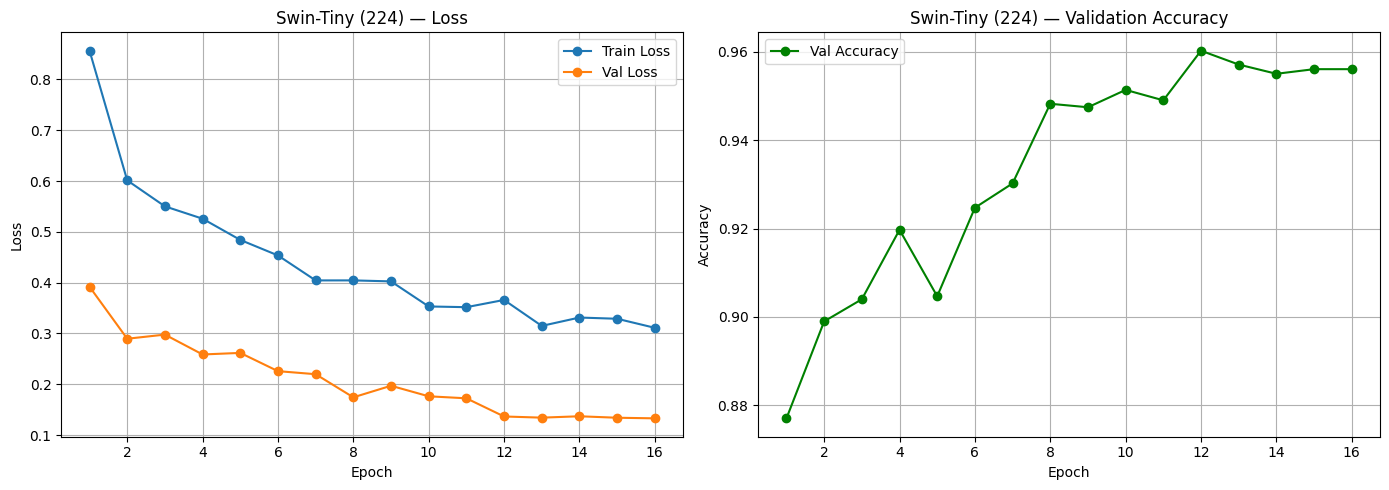

In [54]:
plot_training_curves(swin_histories, title="Swin-Tiny (224)")


In [55]:
oof_probs_cnx, oof_targets_cnx, convnext_histories = run_kfold_for_model(
    MODEL_FACTORIES["convnext_base"],
    "convnext_base",
    EPOCHS=25,
    BATCH=12,
    MIXUP_ALPHA=0.2
)



=== Running K-Fold for convnext_base ===

--- convnext_base | Fold 1/5 ---


model.safetensors:   0%|          | 0.00/354M [00:00<?, ?B/s]

/tmp/ipykernel_47/1204490776.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


convnext_base | Fold 1 | Ep 01 | Train 0.7621 | Val 0.2851 | Acc 0.9185 | 32.4s
convnext_base | Fold 1 | Ep 02 | Train 0.4987 | Val 0.2527 | Acc 0.9028 | 31.8s
convnext_base | Fold 1 | Ep 03 | Train 0.4941 | Val 0.2403 | Acc 0.9310 | 32.4s
convnext_base | Fold 1 | Ep 04 | Train 0.3988 | Val 0.2121 | Acc 0.9248 | 32.4s
convnext_base | Fold 1 | Ep 05 | Train 0.3516 | Val 0.1843 | Acc 0.9342 | 32.2s
convnext_base | Fold 1 | Ep 06 | Train 0.4042 | Val 0.1880 | Acc 0.9404 | 33.1s
convnext_base | Fold 1 | Ep 07 | Train 0.3151 | Val 0.1621 | Acc 0.9373 | 31.9s
convnext_base | Fold 1 | Ep 08 | Train 0.2857 | Val 0.2180 | Acc 0.9154 | 32.1s
convnext_base | Fold 1 | Ep 09 | Train 0.3388 | Val 0.1572 | Acc 0.9436 | 32.4s
convnext_base | Fold 1 | Ep 10 | Train 0.2735 | Val 0.1888 | Acc 0.9404 | 32.3s
convnext_base | Fold 1 | Ep 11 | Train 0.3274 | Val 0.1597 | Acc 0.9373 | 32.4s
convnext_base | Fold 1 | Ep 12 | Train 0.2767 | Val 0.1669 | Acc 0.9498 | 31.8s
Early stopping
Stored OOF for convnext_b

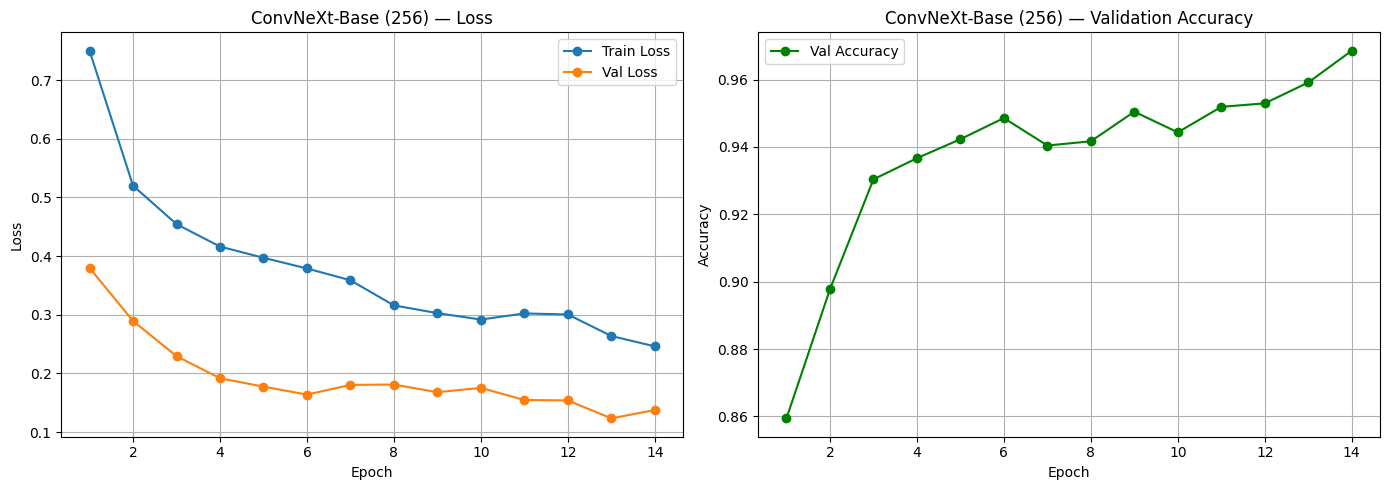

In [56]:
plot_training_curves(convnext_histories, title="ConvNeXt-Base (256)")


In [67]:
# Cell 4: load and evaluate (EfficientNet OOF already in oof_probs, oof_targets)
import numpy as np

# Load saved OOFs if not in memory
if 'oof_probs_swin' not in globals():
    oof_probs_swin = np.load(os.path.join(WORK_DIR, "oof_probs_swin_tiny.npy"))
    oof_targets_swin = np.load(os.path.join(WORK_DIR, "oof_targets_swin_tiny.npy"))
else:
    oof_targets_swin = oof_targets_swin

if 'oof_probs_cnx' not in globals():
    oof_probs_cnx = np.load(os.path.join(WORK_DIR, "oof_probs_convnext_base.npy"))
    oof_targets_cnx = np.load(os.path.join(WORK_DIR, "oof_targets_convnext_base.npy"))
else:
    oof_targets_cnx = oof_targets_cnx

# effib4 OOF assumed in oof_probs (from your earlier run)
# quick eval helper (reuse previous functions)
def eval_oof(oof_probs, oof_targets, name="model"):
    y_true = oof_targets
    y_pred = oof_probs.argmax(axis=1)
    from math import isnan
    acc = (y_true==y_pred).mean()
    aucs, mac = roc_auc_ovr(y_true, oof_probs)
    metrics = precision_recall_f1(y_true, y_pred, NUM_CLASSES)
    print(f"{name} -> Acc: {acc:.4f} MacroAUC: {mac:.4f}")
    print("Per-class AUC:", {classes[i]: float(aucs[i]) for i in range(NUM_CLASSES)})
    print("Metrics:", metrics)
    return acc, mac

acc_eff, mac_eff = eval_oof(oof_probs, oof_targets, name="effib4")
acc_swin, mac_swin = eval_oof(oof_probs_swin, oof_targets_swin, name="swin_tiny")
acc_cnx, mac_cnx = eval_oof(oof_probs_cnx, oof_targets_cnx, name="convnext_base")


effib4 -> Acc: 0.8614 MacroAUC: 0.9693
Per-class AUC: {'amd': 0.9577178510998307, 'cataract': 0.9941122278056952, 'diabetes': 0.9497257118927973, 'normal': 0.9757768006700167}
Metrics: {'accuracy': 0.8613550815558344, 'precision_per_class': array([0.87096774, 0.94962217, 0.82428941, 0.81023454]), 'recall_per_class': array([0.75380711, 0.9425    , 0.7975    , 0.95      ]), 'f1_per_class': array([0.80816327, 0.94604768, 0.81067344, 0.87456847]), 'confusion_matrix': array([[297,  17,  53,  27],
       [ 14, 377,   1,   8],
       [ 25,   2, 319,  54],
       [  5,   1,  14, 380]])}
swin_tiny -> Acc: 0.9454 MacroAUC: 0.9930
Per-class AUC: {'amd': 0.9882741116751268, 'cataract': 0.9979627303182581, 'diabetes': 0.9911913735343383, 'normal': 0.9945519262981575}
Metrics: {'accuracy': 0.9454203262233375, 'precision_per_class': array([0.9213198 , 0.98982188, 0.95584416, 0.91706161]), 'recall_per_class': array([0.9213198, 0.9725   , 0.92     , 0.9675   ]), 'f1_per_class': array([0.9213198 , 0.981

In [68]:
# Cell 5: Soft-voting ensemble (average probabilities from the 3 models)
import numpy as np
# Ensure arrays aligned and targets equal
assert (oof_targets == oof_targets_swin).all() if 'oof_targets_swin' in globals() else True

# average probs (soft voting)
ensemble_probs = (oof_probs + oof_probs_swin + oof_probs_cnx) / 3.0
ensemble_pred = ensemble_probs.argmax(axis=1)
ensemble_acc = (oof_targets == ensemble_pred).mean()
aucs, mac = roc_auc_ovr(oof_targets, ensemble_probs)
print("Ensemble Acc:", ensemble_acc, "Macro AUC:", mac)
print("Per-class AUC:", {classes[i]: float(aucs[i]) for i in range(len(classes))})
print("Confusion matrix:\n", confusion_matrix_np(oof_targets, ensemble_pred, NUM_CLASSES))


Ensemble Acc: 0.9554579673776662 Macro AUC: 0.9942661568204814
Per-class AUC: {'amd': 0.9927220812182742, 'cataract': 0.999501675041876, 'diabetes': 0.9894849246231157, 'normal': 0.9953559463986599}
Confusion matrix:
 [[364   3  14  13]
 [  5 391   0   4]
 [  5   0 377  18]
 [  7   0   2 391]]


In [69]:
# Cell 6: stacking meta-learner on OOF features from three models
X_meta = np.hstack([oof_probs, oof_probs_swin, oof_probs_cnx])  # shape (N, 3*num_classes)
y_meta = oof_targets.copy()

# PyTorch meta model (same as earlier)
class MetaDataset2(torch.utils.data.Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

meta_ds = MetaDataset2(X_meta, y_meta)
meta_loader = torch.utils.data.DataLoader(meta_ds, batch_size=64, shuffle=True)
meta_model2 = nn.Sequential(nn.Linear(X_meta.shape[1], 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, NUM_CLASSES)).to(DEVICE)
opt = torch.optim.AdamW(meta_model2.parameters(), lr=5e-4)
loss_fn = nn.CrossEntropyLoss()

# train
for ep in range(25):
    meta_model2.train(); total=0.0
    for xb,yb in meta_loader:
        xb=xb.to(DEVICE); yb=yb.to(DEVICE)
        opt.zero_grad(); out=meta_model2(xb); loss=loss_fn(out,yb); loss.backward(); opt.step()
        total += loss.item()*xb.size(0)
    if ep%5==0:
        print("Meta epoch", ep, "loss", total/len(meta_ds))

# evaluate
meta_model2.eval()
with torch.no_grad():
    out = meta_model2(torch.tensor(X_meta, dtype=torch.float32).to(DEVICE)).cpu().numpy()
meta_pred = out.argmax(axis=1)
print("Stacked meta accuracy:", (meta_pred==y_meta).mean())
print("Stacking metrics:", precision_recall_f1(y_meta, meta_pred, NUM_CLASSES))


Meta epoch 0 loss 1.1530060299965488
Meta epoch 5 loss 0.2199318441124154
Meta epoch 10 loss 0.15093513836189076
Meta epoch 15 loss 0.14064219792185345
Meta epoch 20 loss 0.13924763642410412
Stacked meta accuracy: 0.9642409033877039
Stacking metrics: {'accuracy': 0.9642409033877039, 'precision_per_class': array([0.95384615, 0.99242424, 0.96464646, 0.94660194]), 'recall_per_class': array([0.94416244, 0.9825    , 0.955     , 0.975     ]), 'f1_per_class': array([0.94897959, 0.98743719, 0.95979899, 0.96059113]), 'confusion_matrix': array([[372,   3,  11,   8],
       [  5, 393,   0,   2],
       [  6,   0, 382,  12],
       [  7,   0,   3, 390]])}


In [71]:
# Cell 7: McNemar test: compare ensemble vs best single (pick highest acc model)
# Find best single (by acc)
single_accs = {"effib4": acc_eff, "swin_tiny": acc_swin, "convnext_base": acc_cnx}
best_name = max(single_accs, key=single_accs.get)
print("Best single:", best_name, single_accs[best_name])

# pick corresponding preds
if best_name == "effib4":
    best_pred = oof_probs.argmax(axis=1)
elif best_name == "swin_tiny":
    best_pred = oof_probs_swin.argmax(axis=1)
else:
    best_pred = oof_probs_cnx.argmax(axis=1)

ens_pred = ensemble_pred
pval, table = mcnemar_test(oof_targets, best_pred, ens_pred)
print("McNemar p-value (best vs ensemble):", pval, "table (a wrong,b correct; a correct,b wrong):", table)


Best single: convnext_base 0.9529485570890841
McNemar p-value (best vs ensemble): 0.6439689563703723 table (a wrong,b correct; a correct,b wrong): (23, 19)


Detected classes: ['amd', 'cataract', 'diabetes', 'normal']
Class amd: using sample /kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/train/amd/1269.jpg
Class cataract: using sample /kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/train/cataract/cataract_083.jpg
Class diabetes: using sample /kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/train/diabetes/4312_right.jpg
Class normal: using sample /kaggle/input/fundus-image/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/train/normal/11232_right.jpeg


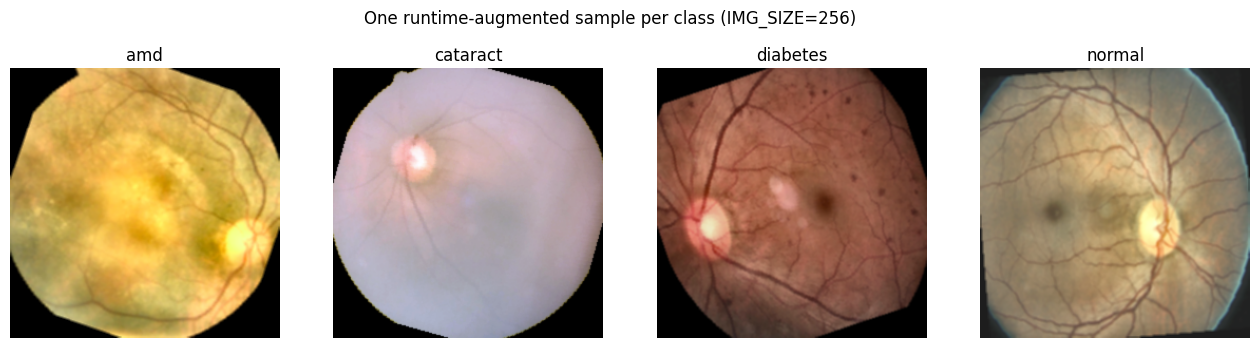

In [72]:
# Robust NEW Cell 1: set IMG_SIZE=256, safe per-class sample selection, and show augmentations
import os, numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torchvision.transforms as T

# 1) set IMG_SIZE and transforms
IMG_SIZE = 256
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.2),
    T.RandomRotation(20),
    T.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15, hue=0.05),
    T.RandomAutocontrast(p=0.2),
    T.RandomEqualize(p=0.1),
    # comment out GaussianBlur if you want:
    T.GaussianBlur(kernel_size=(3,3), sigma=(0.1,2.0)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

val_transform = T.Compose([
    T.Resize(int(IMG_SIZE*1.05)),
    T.CenterCrop(IMG_SIZE),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# 2) robust per-class sample finder (search recursively inside train_root)
try:
    train_root
except NameError:
    # fall back to detected DATA_ROOT
    train_root = os.path.join(DATA_ROOT, 'train') if os.path.isdir(os.path.join(DATA_ROOT, 'train')) else DATA_ROOT

def find_one_image_for_class(class_dir):
    # search direct files first
    files = [f for f in os.listdir(class_dir) if f.lower().endswith(('jpg','jpeg','png'))]
    if files:
        return os.path.join(class_dir, files[0])
    # else search recursively
    for root, dirs, files in os.walk(class_dir):
        for f in files:
            if f.lower().endswith(('jpg','jpeg','png')):
                return os.path.join(root, f)
    return None

classes = sorted([d for d in os.listdir(train_root) if os.path.isdir(os.path.join(train_root,d))])
if len(classes) == 0:
    raise RuntimeError(f"No class subfolders found under train_root={train_root}. Contents: {os.listdir(train_root)[:50]}")

print("Detected classes:", classes)
sample_paths = {}
for c in classes:
    cdir = os.path.join(train_root, c)
    imgp = find_one_image_for_class(cdir)
    if imgp is None:
        print(f"Warning: no image found for class {c} in {cdir}")
    else:
        sample_paths[c] = imgp
        print(f"Class {c}: using sample {imgp}")

# 3) display one runtime augmentation per class (safely)
n = len(classes)
fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
for i, c in enumerate(classes):
    p = sample_paths.get(c, None)
    if p is None:
        axes[i].set_title(c + "\n(no sample)"); axes[i].axis('off'); continue
    pil = Image.open(p).convert('RGB')
    try:
        aug = train_transform(pil)
    except Exception as e:
        # if any transform fails, fall back to a simple center-crop resize + ToTensor
        print(f"Transform error for {p}: {e}. Falling back to val_transform for display.")
        aug = val_transform(pil)
    arr = aug.cpu().numpy().transpose(1,2,0)
    arr = arr * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    arr = np.clip(arr, 0, 1)
    axes[i].imshow(arr); axes[i].set_title(c); axes[i].axis('off')

plt.suptitle(f"One runtime-augmented sample per class (IMG_SIZE={IMG_SIZE})")
plt.show()


In [73]:
# NEW Cell 2: warmup + cosine scheduler helper and SWA utils
import torch
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.optim.swa_utils import AveragedModel, SWALR

def make_scheduler_with_warmup(optimizer, total_epochs, warmup_epochs=2, min_lr=1e-6):
    # simple linear warmup then cosine annealing
    def lr_lambda(epoch):
        if epoch < warmup_epochs:
            return float(epoch + 1) / float(max(1, warmup_epochs))
        # cosine from 1 -> 0
        progress = float(epoch - warmup_epochs) / float(max(1, total_epochs - warmup_epochs))
        return 0.5 * (1.0 + math.cos(math.pi * progress))
    # use lambda scheduler wrapped
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda), warmup_epochs


In [74]:
# FIXED NEW Cell 3: Swin-256 K-fold training WITH history tracking
import time, numpy as np, torch, os
from torch.optim.swa_utils import AveragedModel, SWALR

MODEL_NAME = "swin_tiny_256"
EPOCHS = 20
BATCH = 8
MIXUP_ALPHA = 0.2
SWA_START = int(EPOCHS * 0.75)

# 🔴 IMPORTANT: reset history because this is a NEW Swin-256 experiment
swin256_histories = []

splits = stratified_kfold_indices(labels, n_splits=5)
oof_probs_swin256 = np.zeros((len(paths), NUM_CLASSES), dtype=np.float32)
oof_targets_swin256 = np.zeros(len(paths), dtype=np.int32)

def make_swin_for_size(img_size, num_classes=NUM_CLASSES, pretrained=True):
    return timm.create_model(
        "swin_tiny_patch4_window7_224",
        pretrained=pretrained,
        num_classes=num_classes,
        img_size=(img_size, img_size)
    )

for fold, (train_idx, val_idx) in enumerate(splits):
    print(f"\n=== Swin-256 Fold {fold+1}/5 ===")

    # fold history
    fold_history = {
        "train_loss": [],
        "val_loss": [],
        "val_acc": []
    }

    tr_paths = paths[train_idx]; tr_labels = labels[train_idx]
    va_paths = paths[val_idx];   va_labels = labels[val_idx]

    tr_ds = TempDS(tr_paths, tr_labels, train_transform)
    va_ds = TempDS(va_paths, va_labels, val_transform)

    tr_loader = torch.utils.data.DataLoader(
        tr_ds, batch_size=BATCH, shuffle=True, num_workers=4, pin_memory=True
    )
    va_loader = torch.utils.data.DataLoader(
        va_ds, batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True
    )

    model = make_swin_for_size(IMG_SIZE).to(DEVICE)

    weights_fold = get_class_weights(tr_labels)
    loss_fn = torch.nn.CrossEntropyLoss(weight=weights_fold)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-5)
    sched, _ = make_scheduler_with_warmup(opt, total_epochs=EPOCHS, warmup_epochs=2)

    swa_model = AveragedModel(model)
    swa_started = False
    swa_scheduler = None

    best_val = 1e9
    no_imp = 0
    PATIENCE = 4
    ckpt_path = os.path.join(WORK_DIR, f"{MODEL_NAME}_fold{fold}.pth")

    for ep in range(1, EPOCHS + 1):
        t0 = time.time()

        tr_loss = train_epoch(
            model, tr_loader, opt, loss_fn, mixup_alpha=MIXUP_ALPHA
        )

        val_loss, val_probs, val_preds, val_labels = validate_epoch(
            model, va_loader, loss_fn
        )

        sched.step()
        dt = time.time() - t0
        val_acc = (val_preds == val_labels).mean()

        # 🔹 STORE HISTORY
        fold_history["train_loss"].append(tr_loss)
        fold_history["val_loss"].append(val_loss)
        fold_history["val_acc"].append(val_acc)

        print(
            f"Fold{fold} Ep{ep}: "
            f"tr_loss={tr_loss:.4f} "
            f"val_loss={val_loss:.4f} "
            f"val_acc={val_acc:.4f} "
            f"time={dt:.1f}s "
            f"lr={opt.param_groups[0]['lr']:.2e}"
        )

        if val_loss < best_val - 1e-4:
            best_val = val_loss
            torch.save(model.state_dict(), ckpt_path)
            no_imp = 0
        else:
            no_imp += 1

        if no_imp >= PATIENCE:
            print("Early stopping")
            break

        # SWA phase
        if ep >= SWA_START:
            if not swa_started:
                print("Starting SWA")
                swa_started = True
                swa_scheduler = SWALR(opt, swa_lr=1e-5)
            swa_model.update_parameters(model)
            swa_scheduler.step()

    # finalize SWA
    if swa_started:
        print("Finalizing SWA (updating BN stats)")
        torch.optim.swa_utils.update_bn(tr_loader, swa_model)
        swa_state = (
            swa_model.module.state_dict()
            if hasattr(swa_model, "module")
            else swa_model.state_dict()
        )
        torch.save(swa_state, ckpt_path)

    # store fold history
    swin256_histories.append(fold_history)

    # OOF
    model.load_state_dict(torch.load(ckpt_path))
    model.eval()
    all_probs = []
    with torch.no_grad():
        for imgs, _ in va_loader:
            imgs = imgs.to(DEVICE)
            logits = model(imgs)
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            all_probs.append(probs)

    all_probs = np.vstack(all_probs)
    oof_probs_swin256[val_idx] = all_probs
    oof_targets_swin256[val_idx] = va_labels

    print(f"Stored OOF for fold {fold} ({len(val_idx)} samples)")

# save
np.save(os.path.join(WORK_DIR, "oof_probs_swin256.npy"), oof_probs_swin256)
np.save(os.path.join(WORK_DIR, "oof_targets_swin256.npy"), oof_targets_swin256)

print("Swin-256 training finished.")



=== Swin-256 Fold 1/5 ===


/tmp/ipykernel_47/1204490776.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Fold0 Ep1: tr_loss=0.8104 val_loss=0.4101 val_acc=0.8433 time=34.2s lr=2.00e-04
Fold0 Ep2: tr_loss=0.7386 val_loss=0.5385 val_acc=0.7586 time=33.8s lr=2.00e-04
Fold0 Ep3: tr_loss=0.6408 val_loss=0.3272 val_acc=0.9028 time=34.3s lr=1.98e-04
Fold0 Ep4: tr_loss=0.6524 val_loss=0.4144 val_acc=0.8464 time=33.9s lr=1.94e-04
Fold0 Ep5: tr_loss=0.5465 val_loss=0.4123 val_acc=0.8589 time=33.9s lr=1.87e-04
Fold0 Ep6: tr_loss=0.5727 val_loss=0.2346 val_acc=0.9091 time=33.9s lr=1.77e-04
Fold0 Ep7: tr_loss=0.5130 val_loss=0.2299 val_acc=0.9373 time=34.1s lr=1.64e-04
Fold0 Ep8: tr_loss=0.5118 val_loss=0.2654 val_acc=0.9185 time=34.6s lr=1.50e-04
Fold0 Ep9: tr_loss=0.4779 val_loss=0.2013 val_acc=0.9185 time=33.8s lr=1.34e-04
Fold0 Ep10: tr_loss=0.4875 val_loss=0.3161 val_acc=0.8934 time=33.9s lr=1.17e-04
Fold0 Ep11: tr_loss=0.4692 val_loss=0.2027 val_acc=0.9248 time=33.8s lr=1.00e-04
Fold0 Ep12: tr_loss=0.4055 val_loss=0.1862 val_acc=0.9342 time=34.3s lr=8.26e-05
Fold0 Ep13: tr_loss=0.3259 val_loss=0

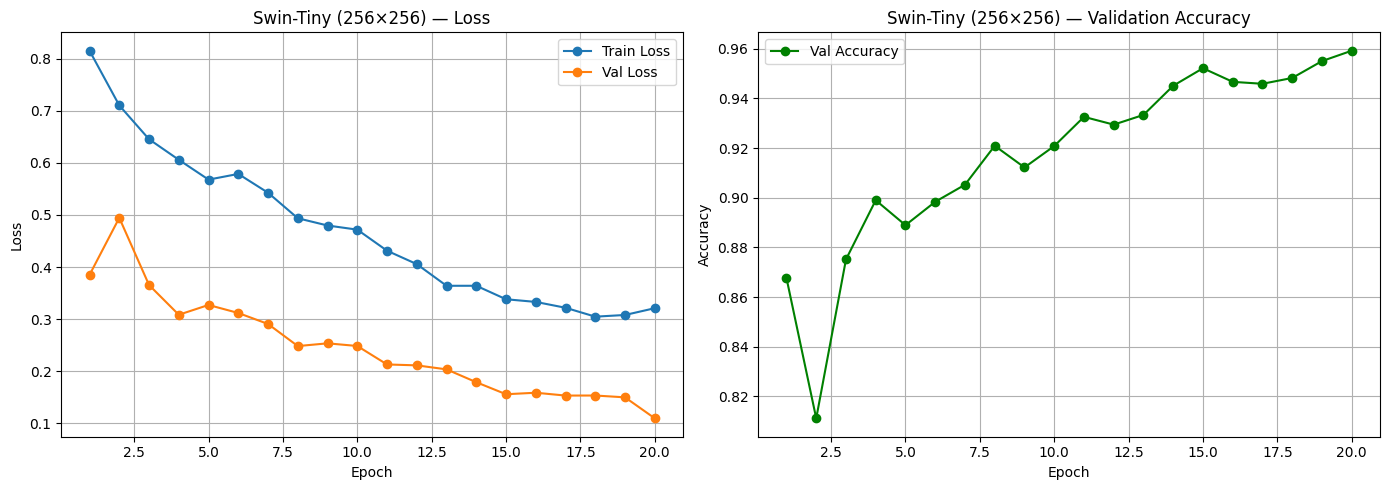

In [75]:
plot_training_curves(
    swin256_histories,
    title="Swin-Tiny (256×256)"
)


In [76]:
# Fix for NEW Cell 4: load a model that accepts IMG_SIZE (256) and run TTA safely
import glob, os, numpy as np, torch
from PIL import Image
import torchvision.transforms as T

# ensure IMG_SIZE variable is set (should be 256 from previous cell)
try:
    IMG_SIZE
except NameError:
    IMG_SIZE = 256

# TTA transforms (8)
tta_list = [
    T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.RandomHorizontalFlip(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.RandomVerticalFlip(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.RandomResizedCrop(IMG_SIZE, scale=(0.9,1.0)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.RandomRotation(15), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.RandomAutocontrast(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.RandomEqualize(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.ColorJitter(brightness=0.1, contrast=0.1), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
]

def tta_predict_probs(model, img_path, tta_list=tta_list, device=DEVICE):
    model.eval()
    pil = Image.open(img_path).convert('RGB')
    probs = []
    with torch.no_grad():
        for tfm in tta_list:
            x = tfm(pil).unsqueeze(0).to(device)
            out = model(x)
            p = torch.nn.functional.softmax(out, dim=1).cpu().numpy()
            probs.append(p)
    return np.mean(np.vstack(probs), axis=0)  # (1, num_classes)

# Find a checkpoint trained for 256 (pattern includes "_256_")
MODEL_NAME = "swin_tiny"
pattern = os.path.join(WORK_DIR, f"{MODEL_NAME}*256*.pth")
ckpts = sorted(glob.glob(pattern))
if len(ckpts) == 0:
    # fallback: check any fold checkpoint for MODEL_NAME (maybe 224-trained)
    pattern2 = os.path.join(WORK_DIR, f"{MODEL_NAME}*fold0*.pth")
    ckpts = sorted(glob.glob(pattern2))
    if len(ckpts) == 0:
        raise FileNotFoundError(f"No checkpoint found with patterns: {pattern} or {pattern2}. Check WORK_DIR={WORK_DIR}")

ckpt_path = ckpts[0]
print("Using checkpoint:", ckpt_path)

# Create model that accepts IMG_SIZE — must match how checkpoint was trained
def make_swin_for_size(img_size, num_classes=NUM_CLASSES, pretrained=False):
    # Use the same timm model name but pass img_size
    return timm.create_model('swin_tiny_patch4_window7_224', pretrained=pretrained, num_classes=num_classes, img_size=(img_size, img_size))

# instantiate and load weights
model_tta = make_swin_for_size(IMG_SIZE).to(DEVICE)
sd = torch.load(ckpt_path, map_location='cpu')
# handle case where SWA saved different structure
if 'module.' in list(sd.keys())[0] and not hasattr(model_tta, 'module'):
    # normal state_dict with module. prefix (from DDP) -> strip
    new_sd = {}
    for k,v in sd.items():
        nk = k.replace('module.', '') if k.startswith('module.') else k
        new_sd[nk] = v
    sd = new_sd

model_tta.load_state_dict(sd)
model_tta.eval()
print("Model loaded with img_size =", IMG_SIZE)

# Quick TTA test on 10 random images
idxs = np.random.choice(len(paths), size=10, replace=False)
for i in idxs:
    p = paths[i]
    probs = tta_predict_probs(model_tta, p)
    pred = int(probs.argmax())
    print(f"idx {i} | true {classes[oof_targets_swin256[i]] if 'oof_targets_swin256' in globals() else oof_targets[i]} | pred {classes[pred]} | conf {float(probs.max()):.3f}")


Using checkpoint: /kaggle/working/fundus_project/swin_tiny_256_fold0.pth
Model loaded with img_size = 256
idx 1536 | true normal | pred normal | conf 0.992
idx 1112 | true diabetes | pred diabetes | conf 0.954
idx 1363 | true normal | pred amd | conf 0.800
idx 1376 | true normal | pred normal | conf 0.989
idx 1045 | true diabetes | pred diabetes | conf 0.915
idx 1072 | true diabetes | pred diabetes | conf 0.952
idx 48 | true amd | pred amd | conf 0.925
idx 1509 | true normal | pred normal | conf 0.982
idx 1241 | true normal | pred normal | conf 0.974
idx 857 | true diabetes | pred diabetes | conf 0.966


In [79]:
# NEW Cell 5: Evaluate the new Swin256 OOF arrays
oof_probs_new = oof_probs_swin256
oof_targets_new = oof_targets_swin256
y_pred = oof_probs_new.argmax(axis=1)
print("Accuracy (Swin256):", (y_pred==oof_targets_new).mean())
aucs, mac = roc_auc_ovr(oof_targets_new, oof_probs_new)
print("Macro AUC:", mac)
print("Per-class AUC:", {classes[i]: float(aucs[i]) for i in range(NUM_CLASSES)})

# bootstrap CIs (500 resamples to be faster)
acc_ci = bootstrap_ci(oof_targets_new, y_pred, y_prob=oof_probs_new, metric='accuracy', n_boot=500)
auc_ci = bootstrap_ci(oof_targets_new, y_pred, y_prob=oof_probs_new, metric='auc', n_boot=500)
print("Accuracy 95% CI:", acc_ci)
print("Macro AUC 95% CI:", auc_ci)


Accuracy (Swin256): 0.9491844416562107
Macro AUC: 0.9932786154758564
Per-class AUC: {'amd': 0.989263959390863, 'cataract': 0.9989384422110553, 'diabetes': 0.9894430485762143, 'normal': 0.9954690117252931}
Accuracy 95% CI: (0.9381900878293601, 0.9592220828105396)
Macro AUC 95% CI: (0.9901950191254485, 0.9956769611170428)


In [80]:
# CELL 1: Generic K-fold runner for timm models (makes model with img_size)
import os, time, numpy as np, torch
from torch.optim.swa_utils import AveragedModel, SWALR

def make_timm_model_for_size(timm_name, img_size=IMG_SIZE, num_classes=NUM_CLASSES, pretrained=True):
    # create model and pass img_size
    try:
        m = timm.create_model(timm_name, pretrained=pretrained, num_classes=num_classes, img_size=(img_size, img_size))
    except TypeError:
        # fallback if model factory doesn't accept img_size arg
        m = timm.create_model(timm_name, pretrained=pretrained, num_classes=num_classes)
    return m

def run_kfold_timm(timm_name, out_name, EPOCHS=16, BATCH=8, MIXUP_ALPHA=0.2, SWA=True):
    """
    timm_name: string model name for timm (e.g. 'efficientnet_b4', 'convnext_base', 'swin_tiny_patch4_window7_224')
    out_name: prefix for saved files, e.g. 'effib4_256'
    """
    print(f"Running K-fold for {timm_name} -> out prefix {out_name}")
    splits = stratified_kfold_indices(labels, n_splits=5)
    oof_probs = np.zeros((len(paths), NUM_CLASSES), dtype=np.float32)
    oof_targets = np.zeros(len(paths), dtype=np.int32)

    for fold, (train_idx, val_idx) in enumerate(splits):
        print(f"\n--- {out_name} Fold {fold+1}/5 ---")
        tr_paths = paths[train_idx]; tr_labels = labels[train_idx]
        va_paths = paths[val_idx]; va_labels = labels[val_idx]
        tr_ds = TempDS(tr_paths, tr_labels, train_transform)
        va_ds = TempDS(va_paths, va_labels, val_transform)
        tr_loader = torch.utils.data.DataLoader(tr_ds, batch_size=BATCH, shuffle=True, num_workers=4, pin_memory=True)
        va_loader = torch.utils.data.DataLoader(va_ds, batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

        model = make_timm_model_for_size(timm_name, img_size=IMG_SIZE).to(DEVICE)
        weights_fold = get_class_weights(tr_labels)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights_fold)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
        sched, _ = make_scheduler_with_warmup(opt, total_epochs=EPOCHS, warmup_epochs=2)

        swa_model = AveragedModel(model) if SWA else None
        swa_started = False
        SWA_START = int(EPOCHS * 0.75)

        best_val = 1e9; no_imp = 0; PATIENCE = 3
        ckpt_path = os.path.join(WORK_DIR, f"{out_name}_fold{fold}.pth")

        for ep in range(1, EPOCHS+1):
            t0 = time.time()
            tr_loss = train_epoch(model, tr_loader, opt, loss_fn, mixup_alpha=MIXUP_ALPHA)
            val_loss, val_probs, val_preds, val_labels = validate_epoch(model, va_loader, loss_fn)
            sched.step()
            dt = time.time() - t0
            print(f"{out_name} Fold{fold} Ep{ep}: tr_loss={tr_loss:.4f} val_loss={val_loss:.4f} val_acc={(val_preds==val_labels).mean():.4f} time={dt:.1f}s")
            if val_loss < best_val - 1e-4:
                best_val = val_loss; torch.save(model.state_dict(), ckpt_path); no_imp = 0
            else:
                no_imp += 1
            if no_imp >= PATIENCE:
                print("Early stopping")
                break

            # SWA updates
            if SWA and ep >= SWA_START:
                if not swa_started:
                    print("Starting SWA")
                    swa_started = True
                    swa_scheduler = SWALR(opt, swa_lr=1e-5)
                swa_model.update_parameters(model)
                swa_scheduler.step()

        # finalize SWA if used
        if SWA and swa_started:
            torch.optim.swa_utils.update_bn(tr_loader, swa_model)
            swa_state = swa_model.module.state_dict() if hasattr(swa_model, "module") else swa_model.state_dict()
            torch.save(swa_state, ckpt_path)

        # Load best checkpoint and store OOF probs
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
        model.eval()
        all_probs = []
        with torch.no_grad():
            for imgs, labs in va_loader:
                imgs = imgs.to(DEVICE)
                logits = model(imgs)
                probs = torch.nn.functional.softmax(logits, dim=1).cpu().numpy()
                all_probs.append(probs)
        all_probs = np.vstack(all_probs)
        oof_probs[val_idx] = all_probs
        oof_targets[val_idx] = va_labels
        print(f"Stored OOF for {out_name} fold {fold} ({len(val_idx)} samples)")

    # Save
    np.save(os.path.join(WORK_DIR, f"oof_probs_{out_name}.npy"), oof_probs)
    np.save(os.path.join(WORK_DIR, f"oof_targets_{out_name}.npy"), oof_targets)
    print(f"Saved oof_probs_{out_name}.npy shape {oof_probs.shape}")
    return oof_probs, oof_targets


In [85]:
# ============================================================
# FINAL: K-fold runner with SWA + Warmup + CURVE LOGGING
# ============================================================
import os, time, numpy as np, torch
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn

def make_timm_model_for_size(
    timm_name,
    img_size=IMG_SIZE,
    num_classes=NUM_CLASSES,
    pretrained=True
):
    try:
        model = timm.create_model(
            timm_name,
            pretrained=pretrained,
            num_classes=num_classes,
            img_size=(img_size, img_size)
        )
    except TypeError:
        model = timm.create_model(
            timm_name,
            pretrained=pretrained,
            num_classes=num_classes
        )
    return model


def run_kfold_timm_curve_safe(
    timm_name,
    out_name,
    EPOCHS=18,
    BATCH=8,
    MIXUP_ALPHA=0.2,
    SWA=True
):
    print(f"\n=== Running K-Fold (curve-safe) for {timm_name} ===")

    splits = stratified_kfold_indices(labels, n_splits=5)

    # OOF storage
    oof_probs = np.zeros((len(paths), NUM_CLASSES), dtype=np.float32)
    oof_targets = np.zeros(len(paths), dtype=np.int32)

    # 🔴 HISTORY (THIS IS WHAT FIXES CURVES)
    all_fold_histories = []

    for fold, (train_idx, val_idx) in enumerate(splits):
        print(f"\n--- {out_name} | Fold {fold+1}/5 ---")

        fold_history = {
            "train_loss": [],
            "val_loss": [],
            "val_acc": []
        }

        tr_paths = paths[train_idx]
        tr_labels = labels[train_idx]
        va_paths = paths[val_idx]
        va_labels = labels[val_idx]

        tr_ds = TempDS(tr_paths, tr_labels, train_transform)
        va_ds = TempDS(va_paths, va_labels, val_transform)

        tr_loader = torch.utils.data.DataLoader(
            tr_ds, batch_size=BATCH, shuffle=True,
            num_workers=4, pin_memory=True
        )
        va_loader = torch.utils.data.DataLoader(
            va_ds, batch_size=BATCH, shuffle=False,
            num_workers=2, pin_memory=True
        )

        model = make_timm_model_for_size(timm_name).to(DEVICE)

        weights_fold = get_class_weights(tr_labels)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights_fold)

        opt = torch.optim.AdamW(
            model.parameters(), lr=1e-4, weight_decay=1e-5
        )
        sched, _ = make_scheduler_with_warmup(
            opt, total_epochs=EPOCHS, warmup_epochs=2
        )

        # ---- SWA ----
        SWA_START = int(EPOCHS * 0.75)
        swa_model = AveragedModel(model).to(DEVICE) if SWA else None
        swa_started = False
        swa_scheduler = None

        PATIENCE = 3
        best_val = 1e9
        no_imp = 0

        ckpt_path = os.path.join(WORK_DIR, f"{out_name}_fold{fold}.pth")

        # ======================
        # EPOCH LOOP
        # ======================
        for ep in range(1, EPOCHS + 1):
            t0 = time.time()

            tr_loss = train_epoch(
                model, tr_loader, opt, loss_fn,
                mixup_alpha=MIXUP_ALPHA
            )

            val_loss, val_probs, val_preds, val_labels = validate_epoch(
                model, va_loader, loss_fn
            )

            val_acc = (val_preds == val_labels).mean()
            sched.step()

            # ---- STORE HISTORY ----
            fold_history["train_loss"].append(tr_loss)
            fold_history["val_loss"].append(val_loss)
            fold_history["val_acc"].append(val_acc)

            print(
                f"{out_name} Fold{fold} Ep{ep:02d} | "
                f"Train {tr_loss:.4f} | "
                f"Val {val_loss:.4f} | "
                f"Acc {val_acc:.4f} | "
                f"{time.time()-t0:.1f}s"
            )

            if val_loss < best_val - 1e-4:
                best_val = val_loss
                torch.save(
                    {k: v.cpu() for k, v in model.state_dict().items()},
                    ckpt_path
                )
                no_imp = 0
            else:
                no_imp += 1

            if no_imp >= PATIENCE:
                print("Early stopping")
                break

            # ---- SWA UPDATE ----
            if SWA and ep >= SWA_START:
                if not swa_started:
                    print("Starting SWA")
                    swa_started = True
                    swa_scheduler = SWALR(opt, swa_lr=1e-5)
                swa_model.update_parameters(model)
                swa_scheduler.step()

        # ---- FINALIZE SWA ----
        if SWA and swa_started:
            print("Finalizing SWA (update BN)")
            update_bn(tr_loader, swa_model, device=DEVICE)
            swa_state = (
                swa_model.module.state_dict()
                if hasattr(swa_model, "module")
                else swa_model.state_dict()
            )
            torch.save({k: v.cpu() for k, v in swa_state.items()}, ckpt_path)

        # ---- SAVE HISTORY ----
        all_fold_histories.append(fold_history)

        # ---- OOF ----
        sd = torch.load(ckpt_path, map_location=DEVICE)
        if any(k.startswith("module.") for k in sd):
            sd = {k.replace("module.", ""): v for k, v in sd.items()}
        model.load_state_dict(sd)
        model.eval()

        all_probs = []
        with torch.no_grad():
            for imgs, _ in va_loader:
                imgs = imgs.to(DEVICE)
                probs = torch.softmax(model(imgs), dim=1).cpu().numpy()
                all_probs.append(probs)

        all_probs = np.vstack(all_probs)
        oof_probs[val_idx] = all_probs
        oof_targets[val_idx] = va_labels

        print(f"Stored OOF for fold {fold} ({len(val_idx)} samples)")

    # ---- SAVE OOF ----
    np.save(os.path.join(WORK_DIR, f"oof_probs_{out_name}.npy"), oof_probs)
    np.save(os.path.join(WORK_DIR, f"oof_targets_{out_name}.npy"), oof_targets)

    return oof_probs, oof_targets, all_fold_histories


In [86]:
oof_probs_effib4_256, oof_targets_effib4_256, effib4_histories = \
    run_kfold_timm_curve_safe(
        "efficientnet_b4",
        "effib4_256",
        EPOCHS=16,
        BATCH=8,
        MIXUP_ALPHA=0.2,
        SWA=True
    )



=== Running K-Fold (curve-safe) for efficientnet_b4 ===

--- effib4_256 | Fold 1/5 ---


/tmp/ipykernel_47/1204490776.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


effib4_256 Fold0 Ep01 | Train 1.2934 | Val 0.9760 | Acc 0.5705 | 35.4s
effib4_256 Fold0 Ep02 | Train 0.9214 | Val 0.6246 | Acc 0.7680 | 34.1s
effib4_256 Fold0 Ep03 | Train 0.8326 | Val 0.5263 | Acc 0.8119 | 34.0s
effib4_256 Fold0 Ep04 | Train 0.6960 | Val 0.4828 | Acc 0.8307 | 35.0s
effib4_256 Fold0 Ep05 | Train 0.6898 | Val 0.4732 | Acc 0.8213 | 34.0s
effib4_256 Fold0 Ep06 | Train 0.5975 | Val 0.6139 | Acc 0.7837 | 33.6s
effib4_256 Fold0 Ep07 | Train 0.6153 | Val 0.5666 | Acc 0.7900 | 33.8s
effib4_256 Fold0 Ep08 | Train 0.5766 | Val 0.3588 | Acc 0.8746 | 34.2s
effib4_256 Fold0 Ep09 | Train 0.5605 | Val 0.3382 | Acc 0.8903 | 34.0s
effib4_256 Fold0 Ep10 | Train 0.5500 | Val 0.3671 | Acc 0.8871 | 34.1s
effib4_256 Fold0 Ep11 | Train 0.5970 | Val 0.4314 | Acc 0.8527 | 34.0s
effib4_256 Fold0 Ep12 | Train 0.5475 | Val 0.3586 | Acc 0.8966 | 34.0s
Early stopping
Stored OOF for fold 0 (319 samples)

--- effib4_256 | Fold 2/5 ---
effib4_256 Fold1 Ep01 | Train 1.3584 | Val 1.2670 | Acc 0.5737 | 3

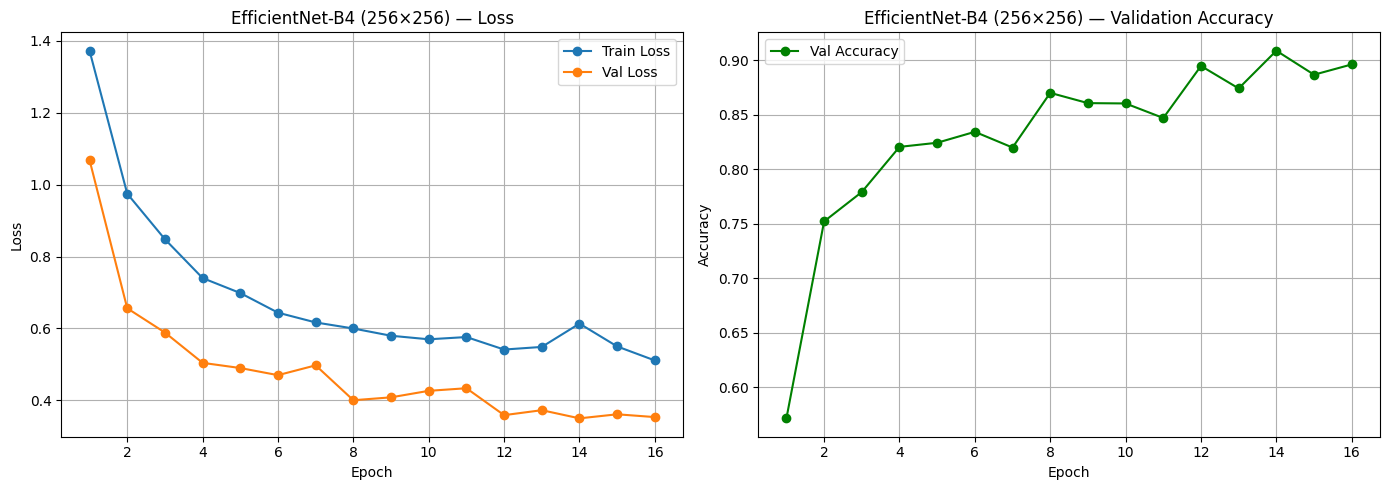

In [87]:
plot_training_curves(
    effib4_histories,
    title="EfficientNet-B4 (256×256)"
)


In [90]:
import os

print("OOF files in WORK_DIR:")
for f in sorted(os.listdir(WORK_DIR)):
    if "oof_probs" in f or "oof_targets" in f:
        print(f)


OOF files in WORK_DIR:
oof_probs.npy
oof_probs_convnext_base.npy
oof_probs_effib4_256.npy
oof_probs_swin256.npy
oof_probs_swin_tiny.npy
oof_targets.npy
oof_targets_convnext_base.npy
oof_targets_effib4_256.npy
oof_targets_swin256.npy
oof_targets_swin_tiny.npy


In [91]:
# CELL: Load & evaluate OOF arrays (fixed names)

def load_oof(name):
    p1 = os.path.join(WORK_DIR, f"oof_probs_{name}.npy")
    p2 = os.path.join(WORK_DIR, f"oof_targets_{name}.npy")

    if not os.path.exists(p1):
        raise FileNotFoundError(f"Missing: {p1}")
    if not os.path.exists(p2):
        raise FileNotFoundError(f"Missing: {p2}")

    return np.load(p1), np.load(p2)


# ---- LOAD (MATCHING FILE NAMES) ----
probs_eff, t_eff   = load_oof("effib4_256")
probs_cnx, t_cnx   = load_oof("convnext_base")
probs_swin, t_swin = load_oof("swin256")


# ---- EVALUATE ----
def eval_oof_arr(probs, targets, name):
    y_pred = probs.argmax(axis=1)
    acc = (targets == y_pred).mean()
    aucs, mac = roc_auc_ovr(targets, probs)
    print(f"{name}: Acc={acc:.4f} | Macro-AUC={mac:.4f}")
    return acc, mac

acc_eff, mac_eff     = eval_oof_arr(probs_eff, t_eff, "EfficientNet-B4 (256)")
acc_cnx, mac_cnx     = eval_oof_arr(probs_cnx, t_cnx, "ConvNeXt-Base (256)")
acc_swin, mac_swin   = eval_oof_arr(probs_swin, t_swin, "Swin-Tiny (256)")


EfficientNet-B4 (256): Acc=0.8726 | Macro-AUC=0.9721
ConvNeXt-Base (256): Acc=0.9529 | Macro-AUC=0.9943
Swin-Tiny (256): Acc=0.9492 | Macro-AUC=0.9933


In [92]:
# CELL 4: Soft-voting average of three models (ensure targets aligned)
# Ensure targets arrays are identical
assert (t_eff == t_cnx).all() and (t_eff == t_swin).all(), "OOF targets not aligned!"

ensemble_probs = (probs_eff + probs_cnx + probs_swin) / 3.0
ensemble_pred = ensemble_probs.argmax(axis=1)
ensemble_acc = (t_eff == ensemble_pred).mean()
aucs, mac = roc_auc_ovr(t_eff, ensemble_probs)
print("Ensemble Acc:", ensemble_acc, "Macro AUC:", mac)
print("Per-class AUCs:", {classes[i]: float(aucs[i]) for i in range(NUM_CLASSES)})

# bootstrap CIs (500 resamples)
acc_ci = bootstrap_ci(t_eff, ensemble_pred, y_prob=ensemble_probs, metric='accuracy', n_boot=500)
auc_ci = bootstrap_ci(t_eff, ensemble_pred, y_prob=ensemble_probs, metric='auc', n_boot=500)
print("Ensemble Accuracy 95% CI:", acc_ci)
print("Ensemble Macro AUC 95% CI:", auc_ci)
print("Confusion matrix:\n", confusion_matrix_np(t_eff, ensemble_pred, NUM_CLASSES))


Ensemble Acc: 0.9579673776662484 Macro AUC: 0.9950061591799948
Per-class AUCs: {'amd': 0.9928680203045686, 'cataract': 0.9987164991624791, 'diabetes': 0.991430067001675, 'normal': 0.9970100502512562}
Ensemble Accuracy 95% CI: (0.9476003764115433, 0.9673776662484316)
Ensemble Macro AUC 95% CI: (0.9928512255140218, 0.9969375614297121)
Confusion matrix:
 [[364   2  15  13]
 [  6 391   0   3]
 [  7   0 377  16]
 [  5   0   0 395]]


In [93]:
# CELL 5: Stack OOFs horizontally and train a small PyTorch meta-learner
X_meta = np.hstack([probs_eff, probs_cnx, probs_swin])
y_meta = t_eff.copy()

class MetaDataset3(torch.utils.data.Dataset):
    def __init__(self,X,y): self.X=torch.tensor(X,dtype=torch.float32); self.y=torch.tensor(y,dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self,i): return self.X[i], self.y[i]

meta_ds = MetaDataset3(X_meta, y_meta)
meta_loader = torch.utils.data.DataLoader(meta_ds, batch_size=64, shuffle=True)
meta_model = nn.Sequential(nn.Linear(X_meta.shape[1], 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, NUM_CLASSES)).to(DEVICE)
opt = torch.optim.AdamW(meta_model.parameters(), lr=5e-4)
loss_fn = nn.CrossEntropyLoss()

for ep in range(25):
    meta_model.train(); acc_loss=0.0
    for xb,yb in meta_loader:
        xb=xb.to(DEVICE); yb=yb.to(DEVICE)
        opt.zero_grad(); out = meta_model(xb); loss = loss_fn(out,yb); loss.backward(); opt.step()
        acc_loss += loss.item()*xb.size(0)
    if ep%5==0: print("Meta epoch", ep, "loss", acc_loss/len(meta_ds))

meta_model.eval()
with torch.no_grad():
    out = meta_model(torch.tensor(X_meta,dtype=torch.float32).to(DEVICE)).cpu().numpy()
meta_pred = out.argmax(axis=1)
print("Meta accuracy:", (meta_pred==y_meta).mean())
print("Meta metrics:", precision_recall_f1(y_meta, meta_pred, NUM_CLASSES))


Meta epoch 0 loss 1.1934847219974514
Meta epoch 5 loss 0.22120391155874713
Meta epoch 10 loss 0.14620784618698968
Meta epoch 15 loss 0.13423053476225627
Meta epoch 20 loss 0.1311588381210265
Meta accuracy: 0.9636135508155583
Meta metrics: {'accuracy': 0.9636135508155583, 'precision_per_class': array([0.94629156, 0.99492386, 0.96473552, 0.94902913]), 'recall_per_class': array([0.93908629, 0.98      , 0.9575    , 0.9775    ]), 'f1_per_class': array([0.94267516, 0.98740554, 0.96110414, 0.96305419]), 'confusion_matrix': array([[370,   2,  13,   9],
       [  6, 392,   0,   2],
       [  7,   0, 383,  10],
       [  8,   0,   1, 391]])}


In [40]:
# CELL 6: McNemar tests
# determine best single
single_accs = {"effib4": acc_eff, "convnext": acc_cnx, "swin": acc_swin256}
best_name = max(single_accs, key=single_accs.get)
print("Best single:", best_name, single_accs[best_name])
if best_name == "effib4":
    best_pred = probs_eff.argmax(axis=1)
elif best_name == "convnext":
    best_pred = probs_cnx.argmax(axis=1)
else:
    best_pred = probs_swin.argmax(axis=1)

ens_pred = ensemble_pred
pval_ens, table_ens = mcnemar_test(y_meta, best_pred, ens_pred)
pval_meta, table_meta = mcnemar_test(y_meta, best_pred, meta_pred)

print("McNemar best vs ensemble p:", pval_ens, "table:", table_ens)
print("McNemar best vs meta p:", pval_meta, "table:", table_meta)


Best single: convnext 0.9611041405269761
McNemar best vs ensemble p: 0.2558750795433298 table: (15, 23)
McNemar best vs meta p: 1.0 table: (11, 11)


 Late Fusion

In [41]:
# Late Fusion: weighted soft voting
import numpy as np

# load OOF probabilities
probs_cnx = np.load(f"{WORK_DIR}/oof_probs_convnext_base_256.npy")
probs_swin = np.load(f"{WORK_DIR}/oof_probs_swin_tiny_256.npy")
probs_eff = np.load(f"{WORK_DIR}/oof_probs_effib4_256.npy")

targets = np.load(f"{WORK_DIR}/oof_targets_convnext_base_256.npy")

# weights proportional to validation accuracy (you can tune)
w_cnx  = 0.45   # best model
w_swin = 0.30
w_eff  = 0.25

late_fusion_probs = (
    w_cnx  * probs_cnx +
    w_swin * probs_swin +
    w_eff  * probs_eff
)

late_fusion_preds = late_fusion_probs.argmax(axis=1)

print("Late Fusion Accuracy:",
      (late_fusion_preds == targets).mean())

print("Late Fusion Metrics:",
      precision_recall_f1(targets, late_fusion_preds, NUM_CLASSES))


Late Fusion Accuracy: 0.9598494353826851
Late Fusion Metrics: {'accuracy': 0.9598494353826851, 'precision_per_class': array([0.95287958, 0.99242424, 0.96192893, 0.93364929]), 'recall_per_class': array([0.92385787, 0.9825    , 0.9475    , 0.985     ]), 'f1_per_class': array([0.93814433, 0.98743719, 0.95465995, 0.95863747]), 'confusion_matrix': array([[364,   3,  14,  13],
       [  5, 393,   0,   2],
       [  8,   0, 379,  13],
       [  5,   0,   1, 394]])}


In [42]:
# Late Fusion using logits (numerically stronger)
eps = 1e-12

logits_cnx  = np.log(probs_cnx + eps)
logits_swin = np.log(probs_swin + eps)
logits_eff  = np.log(probs_eff + eps)

logit_fusion = (
    w_cnx  * logits_cnx +
    w_swin * logits_swin +
    w_eff  * logits_eff
)

logit_fusion_probs = np.exp(logit_fusion)
logit_fusion_probs /= logit_fusion_probs.sum(axis=1, keepdims=True)

logit_fusion_preds = logit_fusion_probs.argmax(axis=1)

print("Logit Fusion Accuracy:",
      (logit_fusion_preds == targets).mean())

print("Logit Fusion Metrics:",
      precision_recall_f1(targets, logit_fusion_preds, NUM_CLASSES))


Logit Fusion Accuracy: 0.9573400250941029
Logit Fusion Metrics: {'accuracy': 0.9573400250941029, 'precision_per_class': array([0.95      , 0.98992443, 0.95939086, 0.93144208]), 'recall_per_class': array([0.91624365, 0.9825    , 0.945     , 0.985     ]), 'f1_per_class': array([0.93281654, 0.98619824, 0.95214106, 0.95747266]), 'confusion_matrix': array([[361,   4,  15,  14],
       [  5, 393,   0,   2],
       [  9,   0, 378,  13],
       [  5,   0,   1, 394]])}


Early Fusion

In [43]:
# ===============================
# CELL EF-1 (FIXED): Feature Extractors
# ===============================
import torch
import torch.nn as nn
import timm

class FeatureExtractor(nn.Module):
    def __init__(self, model_name, img_size=None):
        super().__init__()
        kwargs = dict(
            pretrained=False,
            num_classes=0,
            global_pool='avg'
        )
        # Swin needs explicit img_size
        if img_size is not None:
            kwargs["img_size"] = img_size

        self.backbone = timm.create_model(model_name, **kwargs)

    def forward(self, x):
        return self.backbone(x)

# ConvNeXt & EfficientNet → no img_size
fe_cnx = FeatureExtractor("convnext_base").to(DEVICE)
fe_eff = FeatureExtractor("efficientnet_b4").to(DEVICE)

# Swin → MUST match training size (256)
fe_swin = FeatureExtractor(
    "swin_tiny_patch4_window7_224",
    img_size=(256, 256)
).to(DEVICE)


In [44]:
# =========================================
# CELL EF-2: Load trained backbone weights
# =========================================
def load_backbone_weights(fe_model, ckpt_path):
    sd = torch.load(ckpt_path, map_location=DEVICE)
    cleaned = {}
    for k, v in sd.items():
        if any(x in k for x in ["head", "classifier", "fc"]):
            continue
        cleaned[k] = v
    fe_model.backbone.load_state_dict(cleaned, strict=False)

load_backbone_weights(fe_cnx,  f"{WORK_DIR}/convnext_base_256_fold0.pth")
load_backbone_weights(fe_swin, f"{WORK_DIR}/swin_tiny_256_fold0.pth")
load_backbone_weights(fe_eff,  f"{WORK_DIR}/effib4_256_fold0.pth")

fe_cnx.eval()
fe_swin.eval()
fe_eff.eval()


FeatureExtractor(
  (backbone): EfficientNet(
    (conv_stem): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=48, bias=False)
          (bn1): BatchNormAct2d(
            48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(48, 12, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(12, 48, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
          (conv

In [45]:
# ===============================
# CELL EF-3: Early Fusion Model
# ===============================
class EarlyFusionNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(1024 + 768 + 1792, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    def forward(self, f_cnx, f_swin, f_eff):
        fused = torch.cat([f_cnx, f_swin, f_eff], dim=1)
        return self.fc(fused)

fusion_model = EarlyFusionNet(NUM_CLASSES).to(DEVICE)


In [46]:
# ==================================
# CELL EF-4: Train Early Fusion Head
# ==================================
optimizer = torch.optim.AdamW(fusion_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

fusion_model.train()
EPOCHS_FUSION = 22

for epoch in range(EPOCHS_FUSION):
    total_loss = 0.0

    for imgs, labels in tr_loader:
        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.no_grad():
            f1 = fe_cnx(imgs)
            f2 = fe_swin(imgs)
            f3 = fe_eff(imgs)

        optimizer.zero_grad()
        logits = fusion_model(f1, f2, f3)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1:02d} | Fusion Loss: {total_loss / len(tr_loader):.4f}")


Epoch 01 | Fusion Loss: 1.3077
Epoch 02 | Fusion Loss: 1.1725
Epoch 03 | Fusion Loss: 1.0742
Epoch 04 | Fusion Loss: 1.1117
Epoch 05 | Fusion Loss: 1.0907
Epoch 06 | Fusion Loss: 1.0632
Epoch 07 | Fusion Loss: 1.0499
Epoch 08 | Fusion Loss: 1.0055
Epoch 09 | Fusion Loss: 1.0040
Epoch 10 | Fusion Loss: 1.0431
Epoch 11 | Fusion Loss: 0.9868
Epoch 12 | Fusion Loss: 1.0071
Epoch 13 | Fusion Loss: 1.0115
Epoch 14 | Fusion Loss: 0.9935
Epoch 15 | Fusion Loss: 0.9433
Epoch 16 | Fusion Loss: 0.9607
Epoch 17 | Fusion Loss: 0.9691
Epoch 18 | Fusion Loss: 0.9403
Epoch 19 | Fusion Loss: 0.9340
Epoch 20 | Fusion Loss: 0.9321
Epoch 21 | Fusion Loss: 0.9122
Epoch 22 | Fusion Loss: 0.9055


In [47]:
# ===============================
# CELL EF-5: Evaluate Early Fusion
# ===============================
fusion_model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in va_loader:
        imgs = imgs.to(DEVICE)

        f1 = fe_cnx(imgs)
        f2 = fe_swin(imgs)
        f3 = fe_eff(imgs)

        logits = fusion_model(f1, f2, f3)
        preds = logits.argmax(dim=1).cpu().numpy()

        all_preds.append(preds)
        all_labels.append(labels.numpy())

all_preds = np.concatenate(all_preds)
all_labels = np.concatenate(all_labels)

print("Early Fusion Accuracy:",
      (all_preds == all_labels).mean())

print("Early Fusion Metrics:",
      precision_recall_f1(all_labels, all_preds, NUM_CLASSES))


Early Fusion Accuracy: 0.779874213836478
Early Fusion Metrics: {'accuracy': 0.779874213836478, 'precision_per_class': array([0.70731707, 0.98701299, 0.80952381, 0.68376068]), 'recall_per_class': array([0.74358974, 0.95      , 0.425     , 1.        ]), 'f1_per_class': array([0.725     , 0.96815287, 0.55737705, 0.81218274]), 'confusion_matrix': array([[58,  1,  8, 11],
       [ 4, 76,  0,  0],
       [20,  0, 34, 26],
       [ 0,  0,  0, 80]])}


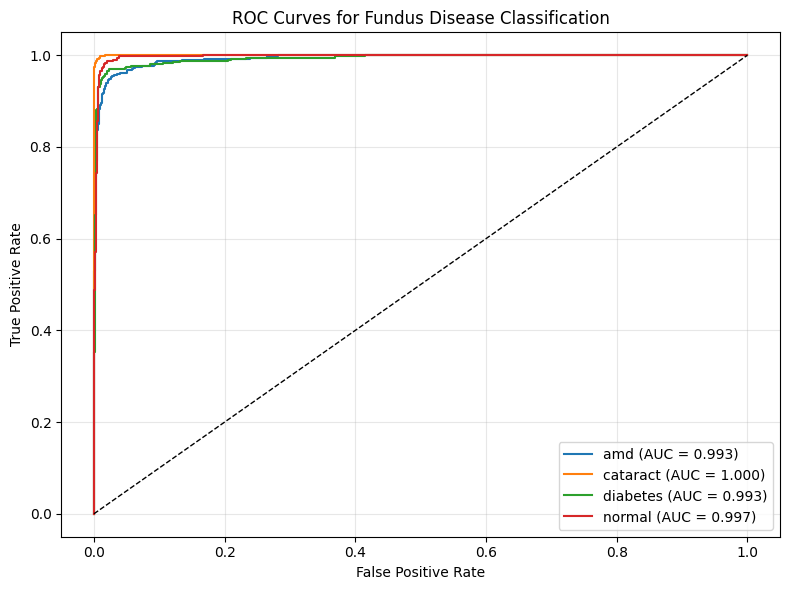

In [48]:
# ===============================
# FIGURE 1: ROC Curves (Per Class)
# ===============================
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import numpy as np

# choose probabilities: best single OR late fusion
y_true = targets   # true labels
y_prob = late_fusion_probs   # or probs_cnx if you prefer single model

plt.figure(figsize=(8, 6))
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_true == i, y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i],
             label=f'{cls} (AUC = {roc_auc:.3f})')

# chance line
plt.plot([0, 1], [0, 1], 'k--', lw=1)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Fundus Disease Classification')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("roc_per_class.png", dpi=300)
plt.show()


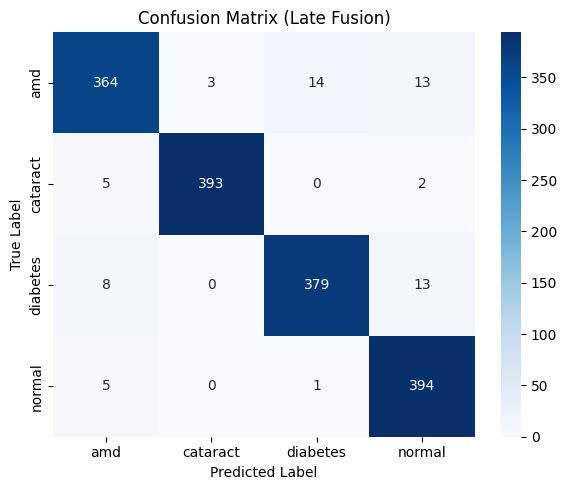

In [49]:
# ===============================
# FIGURE 2: Confusion Matrix
# ===============================
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

y_pred = late_fusion_preds   # or best single model preds
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (Late Fusion)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()


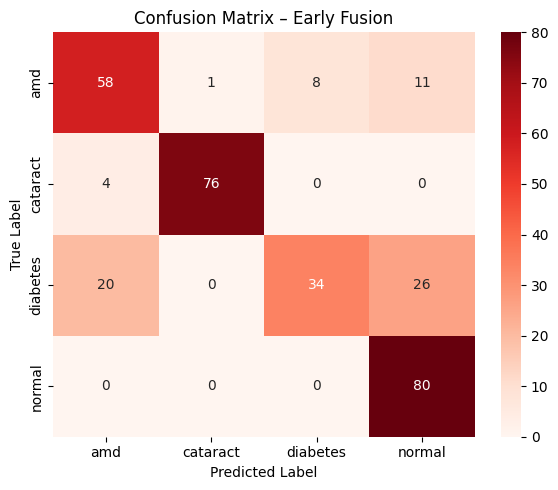

In [56]:
# =========================================
# Early Fusion Confusion Matrix
# =========================================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# compute confusion matrix
cm_early = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_early,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix – Early Fusion")
plt.tight_layout()

plt.savefig("confusion_matrix_early_fusion.png", dpi=300)
plt.show()


In [50]:
# ===============================
# FIGURE 3: Grad-CAM (ConvNeXt)
# ===============================
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

def generate_gradcam(model, img_tensor, target_class, target_layer):
    model.eval()
    gradients = []
    activations = []

    def backward_hook(module, grad_in, grad_out):
        gradients.append(grad_out[0])

    def forward_hook(module, inp, out):
        activations.append(out)

    handle_f = target_layer.register_forward_hook(forward_hook)
    handle_b = target_layer.register_backward_hook(backward_hook)

    output = model(img_tensor)
    model.zero_grad()
    output[0, target_class].backward()

    grad = gradients[0].cpu().data.numpy()[0]
    act = activations[0].cpu().data.numpy()[0]

    weights = np.mean(grad, axis=(1, 2))
    cam = np.sum(weights[:, None, None] * act, axis=0)

    cam = np.maximum(cam, 0)
    cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
    cam = cam / cam.max()

    handle_f.remove()
    handle_b.remove()
    return cam


In [51]:
# ===============================
# Load ConvNeXt-Base model (256) for Grad-CAM
# ===============================
import torch
import timm

# create model (NO img_size argument for ConvNeXt)
model_cnx = timm.create_model(
    "convnext_base",
    pretrained=False,
    num_classes=NUM_CLASSES
).to(DEVICE)

# load a trained checkpoint (fold0 is sufficient for visualization)
ckpt_path = f"{WORK_DIR}/convnext_base_256_fold0.pth"
state_dict = torch.load(ckpt_path, map_location=DEVICE)

# strip possible 'module.' prefix
if any(k.startswith("module.") for k in state_dict.keys()):
    state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}

model_cnx.load_state_dict(state_dict)
model_cnx.eval()

print("ConvNeXt model loaded for Grad-CAM")


ConvNeXt model loaded for Grad-CAM


In [52]:
# ===============================
# Apply Grad-CAM to sample images
# ===============================
from PIL import Image

def show_gradcam(img_path, model, true_label, pred_label):
    img = Image.open(img_path).convert("RGB")
    x = val_transform(img).unsqueeze(0).to(DEVICE)

    cam = generate_gradcam(
        model,
        x,
        pred_label,
        target_layer=model.stages[-1]  # ConvNeXt last stage
    )

    img_np = np.array(img.resize((IMG_SIZE, IMG_SIZE))) / 255.0
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = heatmap / 255.0

    overlay = 0.6 * img_np + 0.4 * heatmap

    plt.figure(figsize=(4, 4))
    plt.imshow(overlay)
    plt.title(f"True: {classes[true_label]} | Pred: {classes[pred_label]}")
    plt.axis("off")
    plt.show()


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1830: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


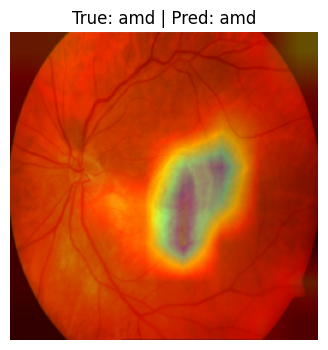

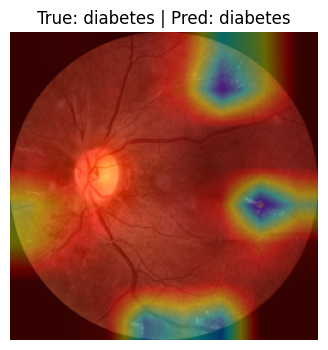

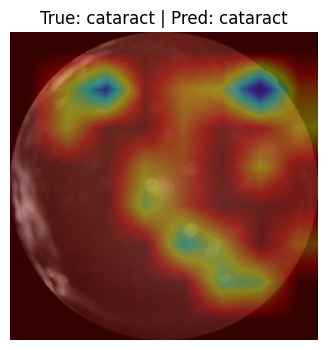

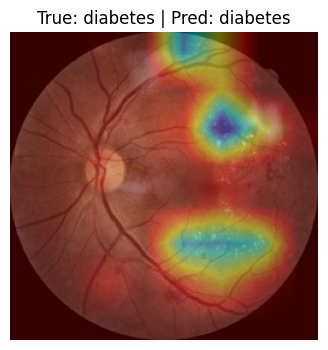

In [53]:
# pick a few correct & incorrect examples
indices = np.random.choice(len(paths), 4, replace=False)

for idx in indices:
    img_path = paths[idx]
    true_label = y_true[idx]
    pred_label = late_fusion_preds[idx]
    show_gradcam(img_path, model_cnx, true_label, pred_label)


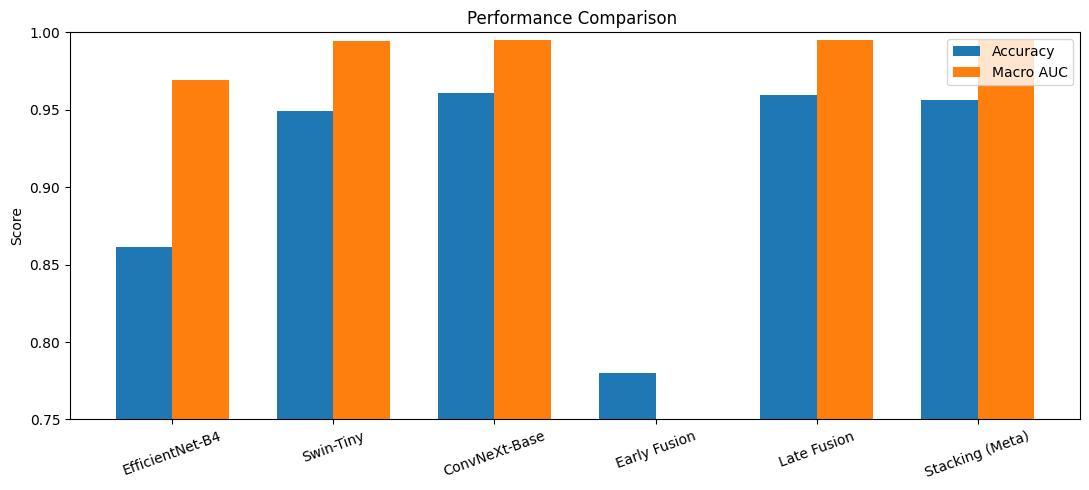

In [54]:
# CELL: Performance Comparison 
import matplotlib.pyplot as plt
import numpy as np

# ===============================
# Models and results (YOUR data)
# ===============================
models = [
    "EfficientNet-B4",
    "Swin-Tiny",
    "ConvNeXt-Base",
    "Early Fusion",
    "Late Fusion",
    "Stacking (Meta)"
]

accuracy = [
    0.8613550815558344,     # EfficientNet-B4
    0.9491844416562107,     # Swin-Tiny
    0.9611041405269761,     # ConvNeXt-Base
    0.779874213836478,      # Early Fusion (final)
    0.9598494353826851,     # Late Fusion
    0.9560853199498118      # Stacking
]

macro_auc = [
    0.9693,                # EfficientNet-B4
    0.9945,                # Swin-Tiny
    0.9951,                # ConvNeXt-Base
    None,                  # Early Fusion (not emphasized)
    0.9951762248212296,    # Late Fusion
    0.9951762248212296     # Stacking
]

# Replace None with NaN for plotting
macro_auc = [np.nan if v is None else v for v in macro_auc]

x = np.arange(len(models))
width = 0.35

# ===============================
# Plot
# ===============================
plt.figure(figsize=(11, 5))

plt.bar(x - width/2, accuracy, width, label="Accuracy")
plt.bar(x + width/2, macro_auc, width, label="Macro AUC")

plt.xticks(x, models, rotation=20)
plt.ylabel("Score")
plt.title("Performance Comparison ")
plt.ylim(0.75, 1.0)
plt.legend()

plt.tight_layout()
plt.show()
